<a href="https://colab.research.google.com/github/jihyeon26/computational-language-technology-hs26/blob/main/stage2/work_packages/stage2_wp3_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3. Comparative Evaluation and Insights
Part 1 trained classical representations on the corpus (Word2Vec, FastText, Doc2Vec). Part 2 adapted compact open models (Qwen3-1.7B and Qwen3-4B) with QLoRA and classified the open-models articles into five themes. This part puts them side by side and uses the best of them to analyse the discourse:
1. **Intrinsic evaluation of words**: do Word2Vec and FastText place similar words close together, in general English and for the terms of the open-models track?
2. **Intrinsic evaluation of articles**: do the article vectors of all representations group articles of the same theme, and separate the open-models articles from the rest of the corpus?
3. **Extrinsic evaluation**: the theme classification of Part 2, completed with the representations Part 2 did not test (TF-IDF, Word2Vec, FastText).
4. **Trade-offs**: model size, performance, training time, inference speed and GPU requirements of every representation.
5. **Insight extraction**: the AI discourse of the whole corpus (Doc2Vec) and the themes of the open-models track over time, by developer region and by model family (best fine-tuned model).

No model is trained in this part, except short timing runs (Section 3.5) and linear classifiers on fixed vectors, so **no GPU is needed**: everything starts from the outputs of Parts 1 and 2.

**Key results**:
1. **Fine-tuning gives the best theme representation**: the QLoRA vectors are the only ones that group articles of the same theme clearly better than the others (kNN accuracy 0.76 vs 0.63 – 0.66, Section 3.3), and Qwen3-4B QLoRA classifies the themes best (macro-F1 0.84, Section 3.4).
2. **A plain TF-IDF baseline comes close**: with a macro-F1 of 0.80 it beats every dense classical representation and both frozen compact models, and it is not significantly worse than Qwen3-4B QLoRA (−4.7 points, p = 0.06), at a fraction of the cost (Sections 3.4 – 3.5).
3. **Pre-training alone does not help**: the frozen compact models score like the representations trained on the corpus, on every intrinsic and extrinsic test.
4. **Cost**: Qwen3-1.7B QLoRA is the best compromise among the compact models: same intrinsic scores and same macro-F1 on the hand-checked articles as Qwen3-4B, with 2.3× shorter training, 2× faster inference and 1.7× less GPU memory (Section 3.5).
5. **Track insight**: the open-models discourse moves from research and China–US rivalry towards **developer tools and agents** (core articles 18% → 29%, mention articles 23% → 36% between the two years); Chinese models are discussed through geopolitics (31% of their articles vs 7% for US models), US and European models through tools and business (Section 3.6).

**Cache**: the long steps (tokenisation of the compared articles, timing runs) save their result on Google Drive and load it when the notebook is run again.

| Team member | Sections | Contribution |
|---|---|---|
| Daliasny Gonzalez Guzman | 3.1 – 3.7 | intrinsic and extrinsic evaluation, comparison of trade-offs (size, performance, training speed, GPU), insight extraction on the open-models track |

## 3.1 Setup
Inputs:
- `corpus_clean.parquet` and `open_models_core.parquet` (Stage 1): the cleaned corpus with the relevance tier, developer regions and model families of every article, and the 1,210 core articles with their Stage 1 topic
- `artifacts/stage2_wp1/splits.parquet` (Part 1): the training / validation split shared by all Stage 2 parts
- `word2vec.model`, `fasttext.model`, `doc_vectors.parquet` (Part 1, Google Drive): the word embeddings and the Doc2Vec vector of every article
- `artifacts/stage2_wp2/labels_checked.csv` (Part 2): the reviewed theme labels of the 1,060 labelled core articles, with their label source
- `llm_doc_vectors_<model>_{base,ft}.parquet` (Part 2, Google Drive): the article vectors of the frozen (`base`) and fine-tuned (`ft`) compact models
- `results_*.csv`, `resources.json`, `predictions_track_qwen3-4b.parquet` (Part 2, Google Drive): scores, time and GPU memory of every step, and the theme predictions for all open-models articles

In [55]:
!pip install -q gensim

In [56]:
from pathlib import Path
import os

# Clone the project repository
REPO = Path("/content/computational-language-technology-hs26")
if REPO.exists():
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/jihyeon26/computational-language-technology-hs26.git {REPO}

# Mount Google Drive (input data and outputs)
from google.colab import drive
drive.mount("/content/drive")

# Inputs: Stage 1 outputs, Part 1 (WP1) and Part 2 (WP2) outputs
DATA_DIR = Path("/content/drive/MyDrive/HSLU/CLT/data/processed")
WP1_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp1")
WP2_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp2")   # outputs that do not depend on the labels
WP2_RUN = WP2_DIR / "checked"                                                      # outputs trained on the reviewed labels

# Outputs of this notebook (also used as cache), with a sub-folder for the figures
OUT_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp3")
FIG = OUT_DIR / "figures"
FIG.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [57]:
# Libraries
import json, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, accuracy_score, silhouette_score, normalized_mutual_info_score,
                             adjusted_rand_score, classification_report)
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
warnings.filterwarnings("ignore", category=FutureWarning)

# Fix the seed (same as Parts 1 and 2)
SEED = 42
np.random.seed(SEED)

# Cosine
def unit(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)

# Save figure and show it
def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

In [58]:
# Stage 1 outputs (API reference pages left out, as in Parts 1 and 2)
corpus = pd.read_parquet(DATA_DIR / "corpus_clean.parquet",
                         columns=["doc_id", "date", "quarter", "title", "text", "om_tier", "om_regions", "om_families",
                                  "is_api_reference"])
corpus = corpus[~corpus["is_api_reference"]].drop(columns="is_api_reference").reset_index(drop=True)
core = pd.read_parquet(DATA_DIR / "open_models_core.parquet", columns=["doc_id", "dominant_topic_label"])
lexicon = json.loads((REPO / "artifacts/stage1_wp1/lexicon/open_models_lexicon.json").read_text(encoding="utf-8"))

# Shared split (Part 1) and reviewed theme labels (Part 2)
splits = pd.read_parquet(REPO / "artifacts/stage2_wp1/splits.parquet")
corpus["split"] = corpus["doc_id"].map(dict(zip(splits["doc_id"], splits["split"])))
corpus["track"] = corpus["om_tier"].ne("none")
labels = pd.read_csv(REPO / "artifacts/stage2_wp2/labels_checked.csv")

LABELS = ["model_families", "china_geopolitics", "research_techniques", "developer_tools", "business_compute"]   # order of Part 2
LABEL_ID = {label: i for i, label in enumerate(LABELS)}
labels["y"] = labels["checked_theme"].map(LABEL_ID).fillna(-1).astype(int)      # "none" -> -1, left out as in Part 2
print(f"{len(corpus):,} articles | labelled core articles: {len(labels):,}")
display(pd.crosstab(labels["checked_theme"], labels["split"], margins=True))

45,462 articles | labelled core articles: 1,060


split,train,validation,All
checked_theme,,,
business_compute,180,43,223
china_geopolitics,149,36,185
developer_tools,188,49,237
model_families,224,56,280
none,10,6,16
research_techniques,97,22,119
All,848,212,1060


The text is normalised and tokenised with the functions of Part 1 (Sections 1.1.2 and 1.1.3), taken from the Part 1 notebook as in Part 2, so that the word and article vectors are computed from exactly the same tokens as in training.

In [59]:
wp1_nb = json.loads((REPO / "stage2/work_packages/stage2_wp1_embeddings.ipynb").read_text(encoding="utf-8"))
for marker in ("def normalise(", "def doc_sentences("):
    exec(next("".join(c["source"]) for c in wp1_nb["cells"]
              if c["cell_type"] == "code" and marker in "".join(c["source"])))

def tokens_of(text):
    return [t for s in doc_sentences(normalise(text)) for t in s]

print(tokens_of("Meta released the open-weight Llama 4 models on Hugging Face.")[:20])

['meta', 'released', 'the', 'open_weight', 'llama', 'models', 'on', 'hugging_face']


### 3.1.1 Representations
All representations are compared on the **same articles**: the 8,037 articles of the Part 1 map (all 4,037 core and mention articles and a fixed random sample of 4,000 other articles), for which Part 2 saved the article vectors of the compact models. Among them are all 1,060 labelled core articles.

| Representation | Type | Article vector |
|---|---|---|
| TF-IDF | discrete (bag of words) | sparse TF-IDF vector of the tokens; vocabulary and IDF fitted on the training split |
| Word2Vec | static word embedding (Part 1) | mean of the word vectors of the article |
| FastText | static word embedding with character n-grams (Part 1) | mean of the word vectors of the article |
| Doc2Vec | document embedding (Part 1) | trained article vector (training split) or inferred vector (validation split) |
| Qwen3-1.7B / Qwen3-4B frozen | pre-trained compact model (Part 2) | mean of the last hidden states over the first 512 tokens |
| Qwen3-1.7B / Qwen3-4B QLoRA | compact model fine-tuned on the themes (Part 2) | same, after fine-tuning |

TF-IDF is added as the discrete baseline of the course (representations of Course 3.0): it shows what plain word counts achieve before any embedding. The mean of word vectors is the simplest way to turn word embeddings into an article vector (Course 3.1).

In [60]:
from gensim.models import Word2Vec, FastText

w2v = Word2Vec.load(str(WP1_DIR / "word2vec.model"))
ft = FastText.load(str(WP1_DIR / "fasttext.model"))
doc_vectors = pd.read_parquet(WP1_DIR / "doc_vectors.parquet")

# Articles of the comparison: those with compact-model vectors (same sample as the Part 1 map)
LLM = {f"Qwen3-{size.upper()} {kind}": (WP2_DIR if tag == "base" else WP2_RUN) / f"llm_doc_vectors_qwen3-{size}_{tag}.parquet"
       for size in ["1.7b", "4b"] for kind, tag in [("frozen", "base"), ("QLoRA", "ft")]}
first = pd.read_parquet(next(iter(LLM.values())), columns=["doc_id"])
docs = first.merge(corpus[["doc_id", "quarter", "title", "text", "om_tier", "track", "split"]], on="doc_id", how="left")
docs = docs.merge(labels[["doc_id", "y", "checked_theme", "label_source"]], on="doc_id", how="left")
docs["y"] = docs["y"].fillna(-1).astype(int)
print(f"Articles of the comparison: {len(docs):,}")
display(pd.crosstab(docs["om_tier"], docs["split"], margins=True))

Articles of the comparison: 8,037


split,train,validation,All
om_tier,,,
core,968,242,1210
mention,2262,565,2827
none,3207,793,4000
All,6437,1600,8037


In [61]:
TOKENS_PATH = OUT_DIR / "tokens_sample.parquet"
if TOKENS_PATH.exists():
    docs["tokens"] = pd.read_parquet(TOKENS_PATH)["tokens"].map(list)
else:
    t0 = time.perf_counter()
    docs["tokens"] = [tokens_of(t) for t in docs["text"]]
    pd.DataFrame({"doc_id": docs["doc_id"], "tokens": docs["tokens"]}).to_parquet(TOKENS_PATH, index=False)
    print(f"Tokenised in {time.perf_counter() - t0:.0f}s")

def mean_vectors(kv, token_lists, oov_vectors):
    """Mean of the word vectors of every article. Word2Vec skips the words without a vector;
    FastText (oov_vectors=True) builds a vector for them from their character n-grams."""
    out = np.zeros((len(token_lists), kv.vector_size), dtype=np.float32)
    cache = {}
    for i, toks in enumerate(token_lists):
        idx = [kv.key_to_index[t] for t in toks if t in kv.key_to_index]
        rows = [kv.vectors[idx]] if idx else []
        if oov_vectors:
            oov = [t for t in toks if t not in kv.key_to_index]
            for t in oov:
                if t not in cache:
                    cache[t] = kv.get_vector(t)
            if oov:
                rows.append(np.vstack([cache[t] for t in oov]))
        if rows:
            out[i] = np.vstack(rows).mean(0)
    return out

# Vectors of every representation, row i = docs.loc[i]
REP = {}
tfidf = TfidfVectorizer(analyzer=lambda toks: toks, min_df=5, max_df=0.5, sublinear_tf=True)
tfidf.fit(docs.loc[docs["split"].eq("train"), "tokens"])
REP["TF-IDF"] = normalize(tfidf.transform(docs["tokens"]))
REP["Word2Vec (mean)"] = mean_vectors(w2v.wv, docs["tokens"], oov_vectors=False)
REP["FastText (mean)"] = mean_vectors(ft.wv, docs["tokens"], oov_vectors=True)
d2v_map = dict(zip(doc_vectors["doc_id"], doc_vectors["vector"]))
REP["Doc2Vec"] = np.vstack([d2v_map[d] for d in docs["doc_id"]]).astype(np.float32)
for name, path in LLM.items():
    v = pd.read_parquet(path)
    assert v["doc_id"].tolist() == docs["doc_id"].tolist(), f"{name}: articles differ from the sample"
    REP[name] = np.vstack(v["vector"].to_numpy()).astype(np.float32)

FAMILY = {"TF-IDF": "discrete", "Word2Vec (mean)": "static word", "FastText (mean)": "static word", "Doc2Vec": "document",
          **{n: ("compact, frozen" if "frozen" in n else "compact, QLoRA") for n in LLM}}
print(pd.DataFrame({"dimensions": {n: X.shape[1] for n, X in REP.items()}, "type": FAMILY}).to_string())

                   dimensions             type
TF-IDF                  29827         discrete
Word2Vec (mean)           100      static word
FastText (mean)           100      static word
Doc2Vec                   100         document
Qwen3-1.7B frozen        2048  compact, frozen
Qwen3-1.7B QLoRA         2048   compact, QLoRA
Qwen3-4B frozen          2560  compact, frozen
Qwen3-4B QLoRA           2560   compact, QLoRA


## 3.2 Intrinsic Evaluation: Words
An intrinsic evaluation tests the vectors themselves, without a downstream task (Course 3.2: similarity). Part 1 compared Word2Vec and FastText by their nearest neighbours; here the comparison is measured with three tests:
1. **General semantic similarity**: two standard benchmarks with human similarity scores for word pairs, WordSim-353 (relatedness: *computer – keyboard*) and SimLex-999 (strict similarity: *smart – intelligent*, but *hard – easy* is dissimilar). The score is the Spearman correlation between the cosine similarity of the vectors and the human scores.
2. **Track-specific similarity**: for every open-model family of the WP1 lexicon, is its developer the closest of all developers (*llama → meta*, *gemma → google*)? And does the analogy *llama : meta = gemma : ?* return *google*?
3. **Category coherence**: do the 116 terms of the Part 1 map (model families, companies, hardware, platforms, …) form groups by category? Measured with the silhouette score and the share of the 5 nearest terms in the same category.

### 3.2.1 General semantic similarity
Word2Vec has no vector for words it saw fewer than 10 times, FastText has one for every word. To compare like with like, both models are scored on the pairs that Word2Vec covers; FastText is also scored on all pairs.

In [62]:
from gensim.test.utils import datapath

def read_pairs(name):
    rows = [l.rstrip("\n").split("\t") for l in open(datapath(name), encoding="utf-8") if not l.startswith("#")]
    return pd.DataFrame([(a.lower(), b.lower(), float(s)) for a, b, s in rows], columns=["w1", "w2", "human"])

def pair_scores(kv, pairs):
    return np.array([kv.similarity(a, b) for a, b in zip(pairs["w1"], pairs["w2"])])

rows = []
for bench in ["wordsim353.tsv", "simlex999.txt"]:
    pairs = read_pairs(bench)
    covered = pairs[[a in w2v.wv.key_to_index and b in w2v.wv.key_to_index for a, b in zip(pairs["w1"], pairs["w2"])]]
    for model_name, kv, subset, label in [("Word2Vec", w2v.wv, covered, "pairs covered by Word2Vec"),
                                         ("FastText", ft.wv, covered, "pairs covered by Word2Vec"),
                                         ("FastText", ft.wv, pairs, "all pairs")]:
        rho, p = spearmanr(pair_scores(kv, subset), subset["human"])
        rows.append({"benchmark": bench.split(".")[0], "model": model_name, "pairs": label,
                     "n": len(subset), "coverage": len(subset) / len(pairs), "spearman": rho, "p": p})
general = pd.DataFrame(rows)
general.to_csv(OUT_DIR / "intrinsic_words_general.csv", index=False)
display(general.round(3))

,benchmark,model,pairs,n,coverage,spearman,p
0,wordsim353,Word2Vec,pairs covered by Word2Vec,339,0.960,0.538,0.0
1,wordsim353,FastText,pairs covered by Word2Vec,339,0.960,0.486,0.0
2,wordsim353,FastText,all pairs,353,1.000,0.481,0.0
3,simlex999,Word2Vec,pairs covered by Word2Vec,985,0.986,0.261,0.0
4,simlex999,FastText,pairs covered by Word2Vec,985,0.986,0.242,0.0
5,simlex999,FastText,all pairs,999,1.000,0.240,0.0


**Interpretation**:
- **Both models capture general word similarity**: all correlations are positive and significant (p < 0.001). Word2Vec scores higher than FastText on both benchmarks (WordSim-353 0.54 vs 0.49, SimLex-999 0.26 vs 0.24, same pairs).
- **Relatedness rather than strict similarity**: the scores on SimLex-999 are about half those on WordSim-353. A skip-gram learns from the words around a word, so words that appear in the same contexts are close even when they are opposites or only related (*hard – easy*, *cup – coffee*). This is the expected behaviour of window-based embeddings.
- **FastText's spelling information costs a little on general words**: the shared character n-grams pull together words that look alike but mean different things, which is the trade-off seen in Part 1 (*deepseek* close to *deepset*). Its advantage, a vector for every word, matters little here: Word2Vec already covers 96 – 99% of the benchmark pairs.
- The scores are lower than those of embeddings trained on general corpora with billions of words; the corpus has about 53 M training tokens of AI news, so general vocabulary is learned only from this domain.

### 3.2.2 Track-specific similarity: model families and their developers
The pairs come from the WP1 lexicon (family → developer). A developer name is turned into a token with the normalisation of Part 1; families whose developer has the same token as the family (*deepseek*, *mistral*, *minimax*) or whose developer has no single-token name in the vocabulary are left out. For each family, all developers of the list are ranked by cosine similarity:
- **hit@1**: the true developer is the closest one; **MRR**: mean of 1 / rank of the true developer;
- **analogy accuracy**: for every two pairs, *developer₁ − family₁ + family₂* is closest to *developer₂* (among the developers, inputs excluded).

In [63]:
GENERIC = {"ai", "labs", "lab", "research", "the", "inc", "inception", "consortia",
           "eu", "swiss", "shanghai"}   # generic words and place names ("Swiss AI Initiative", "Shanghai AI Lab")

def dev_token(name, family):
    for t in tokenize(normalise(str(name))):          # as in Part 1 (Section 1.3.1), a name is one short phrase
        if t not in GENERIC and t != family and t in w2v.wv.key_to_index:
            return t
    return None

dev_pairs = []
for fid, f in lexicon["families"].items():
    if fid not in w2v.wv.key_to_index:
        continue
    d = dev_token(f["developer"].split("/")[0].split("(")[0], fid)
    if d:
        dev_pairs.append((fid, d, f["region"]))
dev_pairs = pd.DataFrame(dev_pairs, columns=["family", "developer", "region"])
DEVS = sorted(dev_pairs["developer"].unique())
print(f"{len(dev_pairs)} family–developer pairs, {len(DEVS)} developers:")
print(", ".join(f"{a}→{b}" for a, b in zip(dev_pairs["family"], dev_pairs["developer"])))

def dev_retrieval(kv):
    D = unit(np.vstack([kv[d] for d in DEVS]))
    ranks = []
    for fam, dev in zip(dev_pairs["family"], dev_pairs["developer"]):
        sims = D @ unit(kv[fam][None])[0]
        ranks.append(1 + int((sims > sims[DEVS.index(dev)]).sum()))
    ranks = np.array(ranks)
    hits = []
    for (f1, d1), (f2, d2) in [(a, b) for a in zip(dev_pairs["family"], dev_pairs["developer"])
                               for b in zip(dev_pairs["family"], dev_pairs["developer"]) if a[1] != b[1]]:
        q = unit((kv[d1] - kv[f1] + kv[f2])[None])[0]
        cand = [d for d in DEVS if d != d1]
        hits.append(cand[int(np.argmax(unit(np.vstack([kv[d] for d in cand])) @ q))] == d2)
    return ranks, np.mean(hits)

assert len(dev_pairs) >= 5, "too few family-developer pairs in the vocabulary"
rows = []
for model_name, kv in [("Word2Vec", w2v.wv), ("FastText", ft.wv)]:
    ranks, analogy = dev_retrieval(kv)
    dev_pairs[f"rank_{model_name}"] = ranks
    rows.append({"model": model_name, "hit@1": (ranks == 1).mean(), "hit@3": (ranks <= 3).mean(),
                 "MRR": (1 / ranks).mean(), "analogy accuracy": analogy})
rows.append({"model": "random ranking", "hit@1": 1 / len(DEVS), "hit@3": 3 / len(DEVS),
             "MRR": np.mean(1 / np.arange(1, len(DEVS) + 1)), "analogy accuracy": 1 / (len(DEVS) - 1)})
developers = pd.DataFrame(rows).set_index("model")
developers.to_csv(OUT_DIR / "intrinsic_words_developers.csv")
display(developers.round(3))
display(dev_pairs)

21 family–developer pairs, 20 developers:
llama→meta, gemma→google, phi→microsoft, nemotron→nvidia, gpt_oss→openai, granite→ibm, olmo→ai2, dbrx→databricks, arctic→snowflake, smollm→hugging_face, eleuther→eleutherai, hermes→nous, grok_open→xai, stable_diffusion→stability, qwen→alibaba, wan→alibaba, hunyuan→tencent, falcon→tii, jais→g42, jamba→ai21, cohere_open→cohere


,hit@1,hit@3,MRR,analogy accuracy
model,,,,
Word2Vec,0.333,0.524,0.492,0.239
FastText,0.286,0.619,0.480,0.364
random ranking,0.050,0.150,0.180,0.053


,family,developer,region,rank_Word2Vec,rank_FastText
0,llama,meta,US,9,8
1,gemma,google,US,10,8
2,phi,microsoft,US,8,10
3,nemotron,nvidia,US,2,1
4,gpt_oss,openai,US,2,2
5,granite,ibm,US,6,14
6,olmo,ai2,US,1,1
7,dbrx,databricks,US,16,6
8,arctic,snowflake,US,6,3
9,smollm,hugging_face,US,1,1


**Interpretation**:
- **Both models link families to their developers far above chance**: the true developer is the closest one for a third of the families (hit@1 0.33 for Word2Vec, 0.29 for FastText, chance 0.05), and among the three closest for half of them or more (0.52 and 0.62).
- **Developers known mainly for their model are found; large companies are not**: *qwen → alibaba*, *olmo → ai2*, *smollm → hugging_face*, *eleuther → eleutherai* and *cohere_open → cohere* rank first in both models, while *llama → meta* (rank 9 / 8), *gemma → google* (10 / 8) and *phi → microsoft* (8 / 10) fail. *Meta*, *Google* and *Microsoft* appear in many other contexts (products, cloud, business, policy), so their vector represents the whole company rather than its open model.
- **FastText is better on analogies** (0.36 vs 0.24, chance 0.05): the relation *family → developer* is more regular in FastText, while Word2Vec ranks the closest developer slightly better. With 21 pairs, the difference between the two models is small and not conclusive.

### 3.2.3 Category coherence of the terms of AI discourse
The terms and categories are those of the Part 1 map (`terms_tsne.csv`): open-model families, openness concepts and ecosystem tools (WP1 lexicon), and the most frequent other AI models, companies, hardware, platforms, architectures and countries (Stage 1 WP2 entities). Part 1 judged the groups visually; here they are measured on the full 100-dimensional vectors (not on the 2-D map, which distorts distances):
- **silhouette** (cosine, −1 to 1): how much closer a term is to its own category than to the nearest other category; > 0 means the categories are separated;
- **5-NN purity**: share of the 5 nearest terms that belong to the same category.

,silhouette,5-NN purity
model,,
Word2Vec,0.092,0.640
FastText,0.078,0.624
random,0.000,0.145


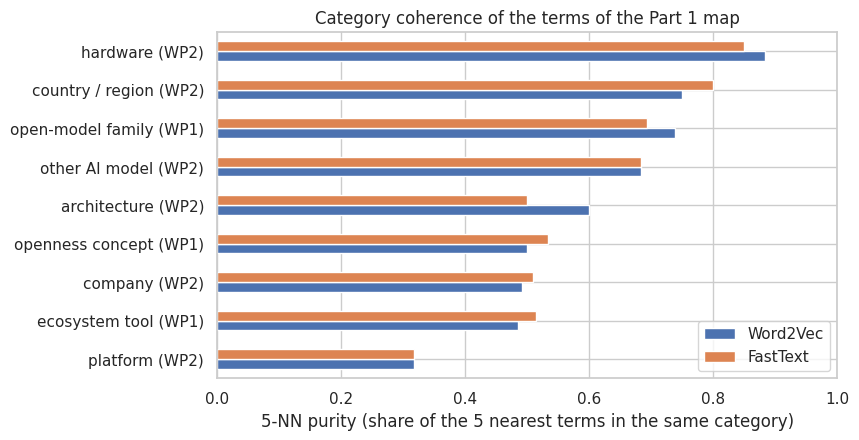

In [64]:
terms = pd.read_csv(REPO / "artifacts/stage2_wp1/terms_tsne.csv")
terms = terms[terms["term"].isin(w2v.wv.key_to_index)].reset_index(drop=True)

def knn_purity(X, y, k=5):
    S = unit(X) @ unit(X).T
    np.fill_diagonal(S, -np.inf)
    nn = np.argsort(-S, axis=1)[:, :k]
    return (np.asarray(y)[nn] == np.asarray(y)[:, None]).mean(1)

rows, per_cat = [], {}
for model_name, kv in [("Word2Vec", w2v.wv), ("FastText", ft.wv)]:
    X = np.vstack([kv[t] for t in terms["term"]])
    pur = knn_purity(X, terms["category"])
    per_cat[model_name] = pd.Series(pur).groupby(terms["category"]).mean()
    rows.append({"model": model_name, "silhouette": silhouette_score(X, terms["category"], metric="cosine"),
                 "5-NN purity": pur.mean()})
shares = terms["category"].value_counts(normalize=True)
rows.append({"model": "random", "silhouette": 0.0, "5-NN purity": float((shares ** 2).sum())})
coherence = pd.DataFrame(rows).set_index("model")
coherence.to_csv(OUT_DIR / "intrinsic_words_categories.csv")
display(coherence.round(3))

per_cat = pd.DataFrame(per_cat).sort_values("Word2Vec")
fig, ax = plt.subplots(figsize=(8, 4.5))
per_cat.plot.barh(ax=ax, color=["#4C72B0", "#DD8452"])
ax.set(xlabel="5-NN purity (share of the 5 nearest terms in the same category)", ylabel="", xlim=(0, 1),
       title="Category coherence of the terms of the Part 1 map")
save_fig(fig, "words_category_purity")

**Interpretation**: the measures confirm the visual reading of the Part 1 map.
- The terms of AI discourse are **organised by category**: 64% (Word2Vec) and 62% (FastText) of the 5 nearest terms belong to the same category, against 15% by chance. The silhouette is positive but small (0.09 and 0.08): categories form neighbourhoods rather than separate groups.
- **Hardware** (0.88 / 0.85), **country / region** (0.75 / 0.80) and **open-model family** (0.74 / 0.69) are the most coherent categories; **platform** is the least (0.32 for both), as its terms are mixed with companies, as seen in Part 1.
- **Architecture** is more coherent in Word2Vec (0.60) than in FastText (0.50), which matches Part 1, where architecture terms formed their own zone in Word2Vec but overlapped the model families in FastText.
- Overall, **Word2Vec is the better word model for this corpus** on similarity and category structure; FastText is useful for unseen names (Part 1) and analogies.

## 3.3 Intrinsic Evaluation: Articles
The article vectors are compared with three intrinsic tasks named in the project brief:
- **Semantic similarity** (retrieval): for an article, are the most similar articles (cosine) about the same theme? Measured with the **kNN accuracy** (the majority theme of the 10 nearest articles is the article's theme) and the **mean average precision of the 10 nearest articles (MAP@10)**.
- **Clustering quality**: K-means with 5 clusters on the vectors; how well do the clusters match the themes (**NMI** and **adjusted Rand index**, mean over 10 runs)? The **silhouette** (cosine) measures how separated the themes are, without clustering.
- **Visualisation**: t-SNE maps of the same articles for every representation.

The themes are the reviewed labels of Part 2. All scores use the **206 labelled validation articles** only: the QLoRA models were trained on the themes of the training articles, so on these the comparison would be unfair. Even on validation articles, the QLoRA vectors have an advantage: they were trained to separate exactly these five themes, while all other representations never saw a theme label.

### 3.3.1 Themes of the open-models articles

In [65]:
val = docs.index[(docs["split"] == "validation") & (docs["y"] >= 0)].to_numpy()
y_val = docs.loc[val, "y"].to_numpy()
print(f"Validation articles with a theme: {len(val)}")

def cosine_matrix(X):
    if hasattr(X, "toarray"):                      # sparse TF-IDF (already unit length)
        return (X @ X.T).toarray()
    Xu = unit(np.asarray(X, dtype=np.float32))
    return Xu @ Xu.T

def retrieval_scores(S, y, k=10):
    """Per-article kNN hit (majority theme of the k nearest) and average precision of the k nearest."""
    S = S.copy()
    np.fill_diagonal(S, -np.inf)
    nn = np.argsort(-S, axis=1)[:, :k]
    same = (y[nn] == y[:, None])
    knn_hit = np.array([np.bincount(y[row], minlength=len(LABELS)).argmax() == t for row, t in zip(nn, y)])
    prec_at = np.cumsum(same, axis=1) / np.arange(1, k + 1)
    ap = (prec_at * same).sum(1) / np.maximum(same.sum(1), 1)
    return knn_hit, ap

def boot_ci(values, n=1000):
    idx = np.random.default_rng(SEED).integers(0, len(values), (n, len(values)))
    return np.percentile(values[idx].mean(1), [2.5, 97.5])

rows, VAL_X = [], {}
for name, X in REP.items():
    Xv = X[val]
    VAL_X[name] = Xv
    S = cosine_matrix(Xv)
    knn_hit, ap = retrieval_scores(S, y_val)
    Xk = Xv if hasattr(Xv, "toarray") else unit(Xv)
    clusters = [KMeans(n_clusters=len(LABELS), n_init=10, random_state=SEED + r).fit_predict(Xk) for r in range(10)]
    lo, hi = boot_ci(knn_hit.astype(float))
    rows.append({"representation": name, "type": FAMILY[name],
                 "kNN accuracy": knn_hit.mean(), "kNN low": lo, "kNN high": hi, "MAP@10": ap.mean(),
                 "silhouette": silhouette_score(Xk, y_val, metric="cosine"),
                 "NMI": np.mean([normalized_mutual_info_score(y_val, c) for c in clusters]),
                 "ARI": np.mean([adjusted_rand_score(y_val, c) for c in clusters])})
intrinsic_docs = pd.DataFrame(rows).set_index("representation")
intrinsic_docs.to_csv(OUT_DIR / "intrinsic_articles_themes.csv")
majority = np.bincount(y_val).max() / len(y_val)
print(f"Chance level of the kNN accuracy (largest theme): {majority:.3f}")
display(intrinsic_docs.round(3))

Validation articles with a theme: 206
Chance level of the kNN accuracy (largest theme): 0.272


,type,kNN accuracy,kNN low,kNN high,MAP@10,silhouette,NMI,ARI
representation,,,,,,,,
TF-IDF,discrete,0.655,0.587,0.723,0.667,0.009,0.274,0.170
Word2Vec (mean),static word,0.636,0.573,0.704,0.689,0.040,0.317,0.212
FastText (mean),static word,0.626,0.563,0.689,0.684,0.038,0.318,0.211
Doc2Vec,document,0.646,0.578,0.714,0.693,0.036,0.338,0.255
Qwen3-1.7B frozen,"compact, frozen",0.646,0.583,0.709,0.641,0.022,0.287,0.161
Qwen3-1.7B QLoRA,"compact, QLoRA",0.762,0.699,0.820,0.722,0.167,0.495,0.438
Qwen3-4B frozen,"compact, frozen",0.660,0.592,0.723,0.642,0.032,0.309,0.201
Qwen3-4B QLoRA,"compact, QLoRA",0.762,0.699,0.820,0.760,0.102,0.484,0.346


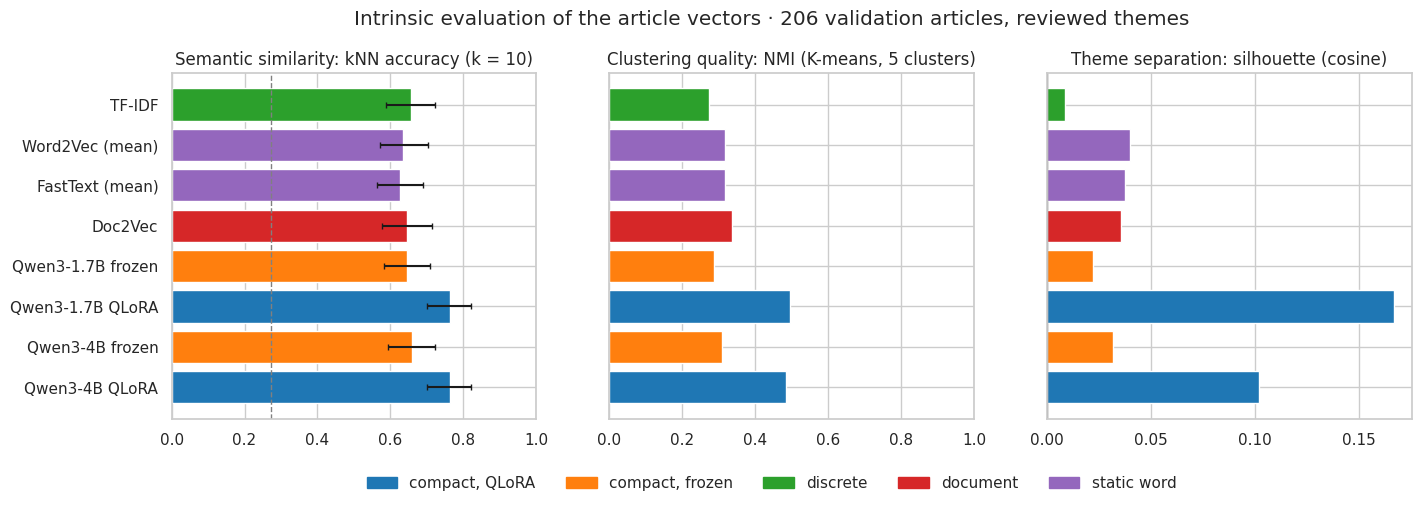

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
order = intrinsic_docs.index[::-1]
type_colors = dict(zip(sorted(set(FAMILY.values())), sns.color_palette("tab10")))
colors = intrinsic_docs.loc[order, "type"].map(type_colors)
axes[0].barh(order, intrinsic_docs.loc[order, "kNN accuracy"], color=colors,
             xerr=[intrinsic_docs.loc[order, "kNN accuracy"] - intrinsic_docs.loc[order, "kNN low"],
                   intrinsic_docs.loc[order, "kNN high"] - intrinsic_docs.loc[order, "kNN accuracy"]], capsize=2)
axes[0].axvline(majority, color="grey", ls="--", lw=1)
axes[0].set(title="Semantic similarity: kNN accuracy (k = 10)", xlim=(0, 1))
axes[1].barh(order, intrinsic_docs.loc[order, "NMI"], color=colors)
axes[1].set(title="Clustering quality: NMI (K-means, 5 clusters)", xlim=(0, 1))
axes[2].barh(order, intrinsic_docs.loc[order, "silhouette"], color=colors)
axes[2].axvline(0, color="grey", lw=1)
axes[2].set(title="Theme separation: silhouette (cosine)")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in type_colors.values()], labels=list(type_colors),
           loc="lower center", ncol=len(type_colors), bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.suptitle("Intrinsic evaluation of the article vectors · 206 validation articles, reviewed themes", y=1.02)
save_fig(fig, "intrinsic_articles")

**Interpretation**:
- **Without theme labels, all representations are close**: the kNN accuracy of the six unsupervised representations lies between 0.63 and 0.66 (chance 0.27), with overlapping intervals. TF-IDF, the mean of word vectors, Doc2Vec and the frozen compact models put articles of the same theme next to each other about equally often.
- **Pre-training on general text does not give better theme neighbourhoods**: the frozen Qwen3 models (0.65 and 0.66) are not better than the representations trained only on this corpus; their NMI (0.29 and 0.31) is even below that of Doc2Vec (0.34), the best unsupervised representation for clustering.
- **QLoRA vectors are clearly better** (kNN accuracy 0.76, NMI 0.50 and 0.48, silhouette 0.17 and 0.10), but they were trained on these five themes, so this measures what fine-tuning learned rather than an unsupervised property. Interestingly, the larger model does not separate the themes better than the smaller one.
- **The themes overlap**: the silhouette of all unsupervised representations is close to 0 (≤ 0.04). The themes are not separate groups of articles; many articles touch several of them (e.g. a model release discussed through its business impact), as the annotation rubric of Part 2 already noted.

### 3.3.2 Open-models articles within AI discourse
The second intrinsic question uses **all 8,037 articles**: are the open-models articles (core, mention, reference) close to each other and apart from the other AI articles? For every article, the share of its 10 nearest articles that are on the same side (open models or not) is measured. About half of this sample are open-models articles, so a random representation scores about 50% (printed below). No representation was trained on this distinction, so the comparison is fair for all of them. The relevance tier was defined by the keywords of the WP1 lexicon, so this test favours representations that weigh the model names.

In [67]:
track = docs["track"].to_numpy()
sub = np.random.default_rng(SEED).choice(len(docs), size=4000, replace=False)   # 4,000 articles keep the matrices small
rows = []
for name, X in REP.items():
    S = cosine_matrix(X[sub])
    np.fill_diagonal(S, -np.inf)
    nn = np.argpartition(-S, 10, axis=1)[:, :10]
    same = (track[sub][nn] == track[sub][:, None]).mean(1)
    rows.append({"representation": name, "type": FAMILY[name],
                 "10-NN purity (all)": same.mean(),
                 "open-models articles": same[track[sub]].mean(),
                 "other articles": same[~track[sub]].mean()})
p = track[sub].mean()
track_sep = pd.DataFrame(rows).set_index("representation")
track_sep.to_csv(OUT_DIR / "intrinsic_articles_track.csv")
print(f"Share of open-models articles in the 4,000 articles: {p:.1%} | random purity: {p**2 + (1-p)**2:.3f}")
display(track_sep.round(3))

Share of open-models articles in the 4,000 articles: 51.1% | random purity: 0.500


,type,10-NN purity (all),open-models articles,other articles
representation,,,,
TF-IDF,discrete,0.672,0.802,0.536
Word2Vec (mean),static word,0.693,0.785,0.597
FastText (mean),static word,0.694,0.784,0.601
Doc2Vec,document,0.716,0.780,0.650
Qwen3-1.7B frozen,"compact, frozen",0.673,0.778,0.563
Qwen3-1.7B QLoRA,"compact, QLoRA",0.671,0.761,0.577
Qwen3-4B frozen,"compact, frozen",0.681,0.786,0.570
Qwen3-4B QLoRA,"compact, QLoRA",0.673,0.756,0.586


**Interpretation**:
- **All representations place open-models articles near each other** (10-NN purity 0.67 – 0.72, chance 0.50), but none separates them well from the rest of AI discourse: about a third of the neighbours are on the other side.
- **Doc2Vec separates the track best** (0.72), mainly because it keeps the other AI articles together (0.65 vs 0.54 – 0.60 for the others). Part 1 judged from the t-SNE map that Doc2Vec does not separate the open-models articles well; measured on all 100 dimensions, it is still the best of the eight, which shows that the t-SNE map understates the separation.
- **TF-IDF groups the open-models articles most** (0.80) but not the other articles (0.54): the open-models articles share rare words (model names, *open-weight*), as expected for tiers defined by keywords.
- **Fine-tuning does not help here**: the QLoRA vectors (0.67) are slightly below the frozen models (0.67 – 0.68). They were trained to separate themes **within** the track, so a China article with or without open models, for example, moves closer to the `china_geopolitics` articles.

### 3.3.3 Visualisation
The 206 validation articles are projected with t-SNE (cosine) for every representation, with the same settings and seed. The colours are the reviewed themes. As in Part 1, the distances between groups on a t-SNE map are not meaningful, only the neighbourhoods.

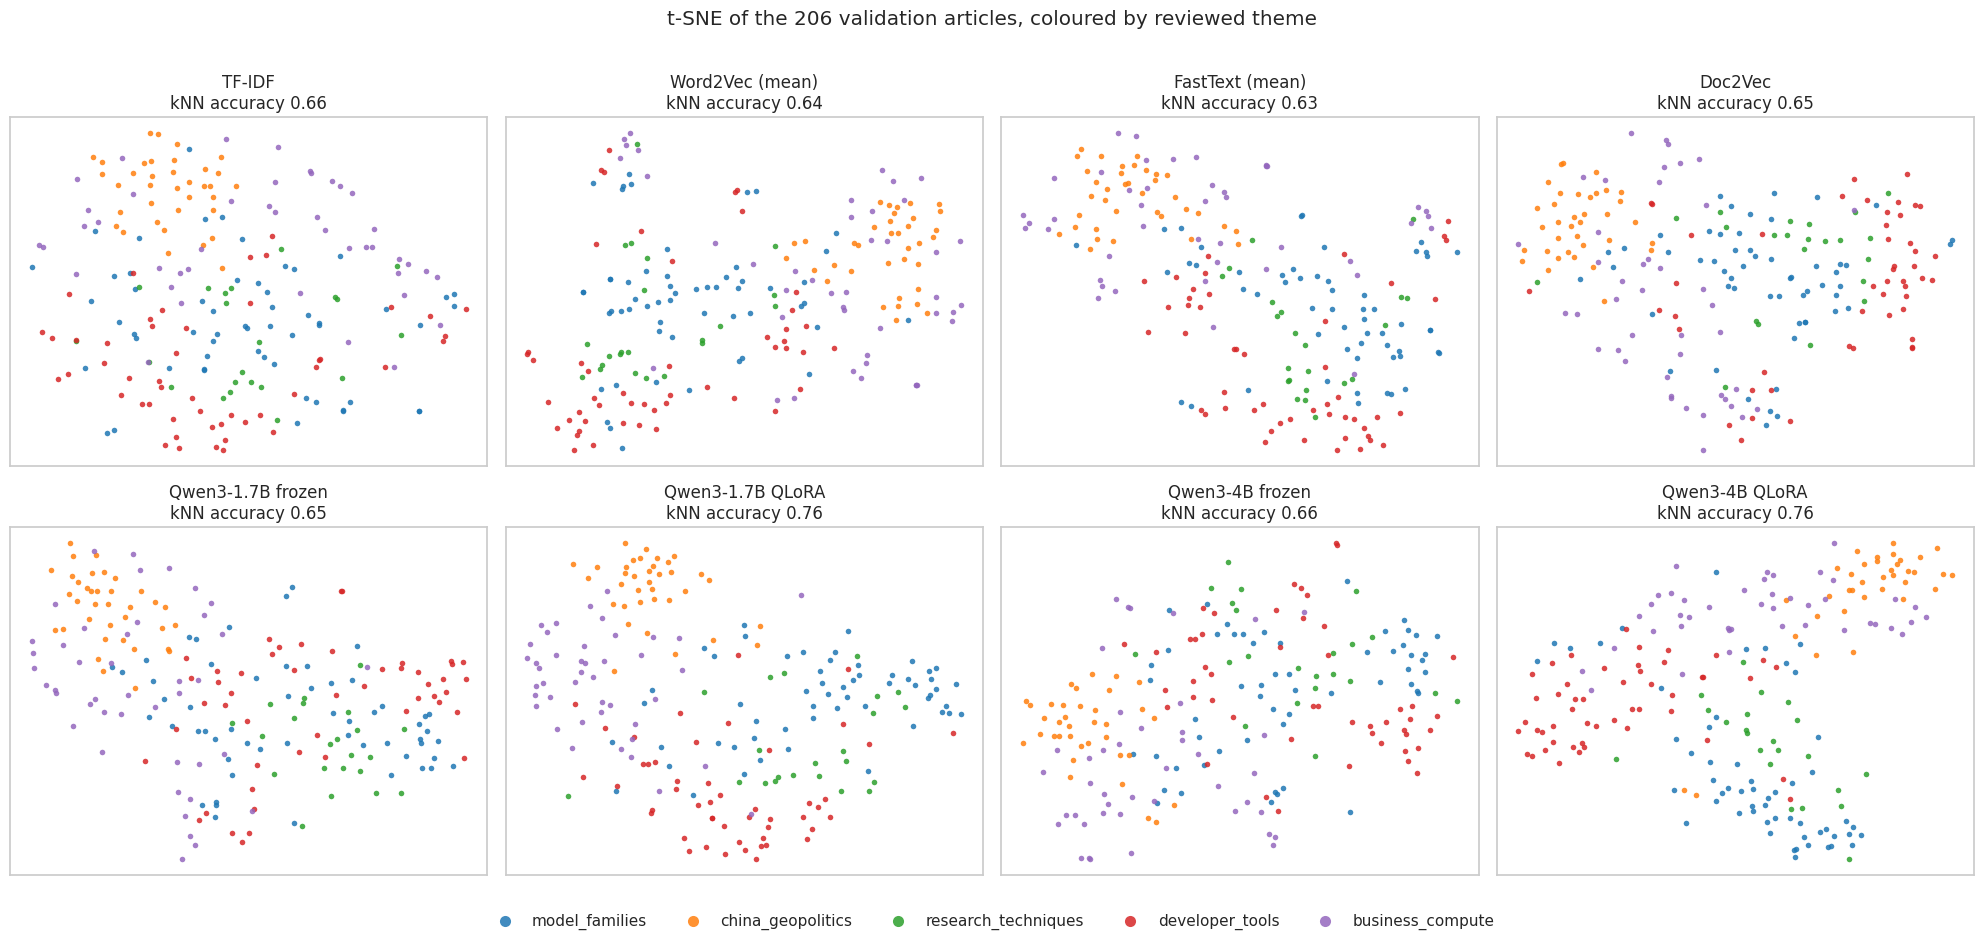

In [68]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
palette = dict(zip(LABELS, sns.color_palette("tab10", len(LABELS))))
theme_names = np.array(LABELS)[y_val]
for ax, (name, Xv) in zip(axes.ravel(), VAL_X.items()):
    Xd = Xv.toarray() if hasattr(Xv, "toarray") else Xv
    xy = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state=SEED).fit_transform(unit(Xd))
    for theme in LABELS:
        m = theme_names == theme
        ax.scatter(xy[m, 0], xy[m, 1], s=16, color=palette[theme], label=theme, alpha=0.85, linewidths=0)
    ax.set(title=f"{name}\nkNN accuracy {intrinsic_docs.loc[name, 'kNN accuracy']:.2f}", xticks=[], yticks=[])
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=5, fontsize=11, frameon=False, markerscale=2)
fig.suptitle("t-SNE of the 206 validation articles, coloured by reviewed theme")
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
save_fig(fig, "tsne_validation_themes")

**Interpretation**:
- In all maps, **`china_geopolitics` forms the clearest zone** (orange), followed by `business_compute` (purple): both themes have a distinctive vocabulary (China, export controls; stocks, revenue, chips).
- `model_families`, `research_techniques` and `developer_tools` are **mixed in the classical and frozen maps**: a model release, a training technique and a tool are reported with similar words.
- The **QLoRA maps** show two large regions, `china_geopolitics` + `business_compute` on one side and `model_families` + `research_techniques` + `developer_tools` on the other, with clearer zones for each theme inside them. `research_techniques` (green) remains spread in all maps: it is the smallest theme and the hardest to classify (Part 2, Section 2.6.2).

## 3.4 Extrinsic Evaluation: Theme Classification
The extrinsic task is the theme classification of Part 2 (Section 2.2): five themes of the open-models discourse, reviewed labels, 848 training articles and 206 validation articles. Part 2 compared Doc2Vec with the compact models; the representations it did not test are added here **with exactly the same protocol** (Section 2.5): article vectors scaled to unit length, a logistic regression with balanced class weights, trained on train + dev and evaluated on validation, macro-F1 with a 95% bootstrap interval, and the score on the 98 articles labelled by hand without the LLM.

The protocol is checked first: Doc2Vec + logistic regression, recomputed here from the Part 1 vectors, must give the macro-F1 of Part 2 (0.749).

In [69]:
fit = docs.index[(docs["split"] == "train") & (docs["y"] >= 0)].to_numpy()
y_fit = docs.loc[fit, "y"].to_numpy()
hand = (docs.loc[val, "label_source"] == "human").to_numpy()

def linear_probe(X_fit, y, X_eval):
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    if hasattr(X_fit, "toarray"):
        clf.fit(X_fit, y)
        return clf.predict(X_eval)
    clf.fit(unit(X_fit), y)
    return clf.predict(unit(X_eval))

def f1_ci(y_true, y_pred, n=1000):
    idx = np.random.default_rng(SEED).integers(0, len(y_true), (n, len(y_true)))
    return np.percentile([f1_score(y_true[i], y_pred[i], average="macro") for i in idx], [2.5, 97.5])

PRED = {}
rows = []
for name in ["TF-IDF", "Word2Vec (mean)", "FastText (mean)", "Doc2Vec"]:
    X = REP[name]
    pred = linear_probe(X[fit], y_fit, X[val])
    PRED[name] = pred
    lo, hi = f1_ci(y_val, pred)
    rows.append({"method": f"{name} + LogReg", "representation": name, "type": FAMILY[name],
                 "accuracy": accuracy_score(y_val, pred), "macro_f1": f1_score(y_val, pred, average="macro"),
                 "f1_low": lo, "f1_high": hi,
                 "macro_f1_hand": f1_score(y_val[hand], pred[hand], average="macro"), "source": "Part 3"})
new = pd.DataFrame(rows)
check = new.loc[new["representation"] == "Doc2Vec", "macro_f1"].item()
print(f"Doc2Vec + LogReg recomputed: {check:.3f} (Part 2: 0.749) -> protocol reproduced: {abs(check - 0.749) < 0.002}")

Doc2Vec + LogReg recomputed: 0.749 (Part 2: 0.749) -> protocol reproduced: True


,type,accuracy,macro_f1,f1_low,f1_high,macro_f1_hand,source
method,,,,,,,
Qwen3-4B QLoRA,"compact, QLoRA",0.850,0.843,0.786,0.891,0.788,Part 2
Qwen3-1.7B QLoRA,"compact, QLoRA",0.816,0.804,0.746,0.855,0.796,Part 2
TF-IDF + LogReg,discrete,0.806,0.796,0.733,0.851,0.754,Part 3
Qwen3-4B frozen + LogReg,"compact, frozen",0.748,0.752,0.691,0.805,0.754,Part 2
Doc2Vec + LogReg,document,0.757,0.749,0.683,0.805,0.740,Part 3
Qwen3-1.7B frozen + LogReg,"compact, frozen",0.733,0.738,0.677,0.792,0.713,Part 2
FastText (mean) + LogReg,static word,0.738,0.727,0.660,0.785,0.743,Part 3
Word2Vec (mean) + LogReg,static word,0.738,0.725,0.659,0.782,0.729,Part 3


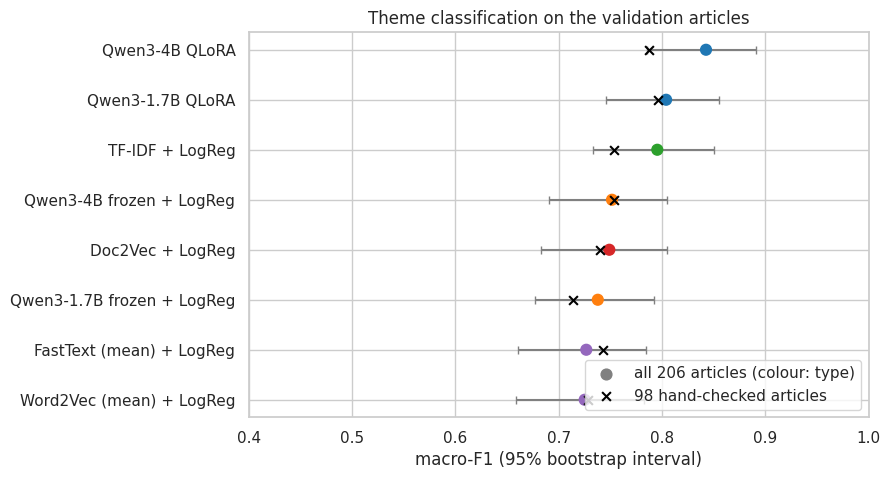

In [70]:
# Scores of Part 2 (same validation articles, same protocol)
wp2 = pd.read_csv(WP2_RUN / "results_validation.csv")
wp2_hand = pd.read_csv(WP2_RUN / "results_robustness.csv", index_col=0)
wp2 = wp2[~wp2["method"].str.startswith("Doc2Vec")].copy()
wp2["representation"] = (wp2["method"].str.replace(" + LogReg", "", regex=False).str.replace("qwen3-", "Qwen3-")
                         .str.replace("1.7b", "1.7B").str.replace("4b", "4B"))
wp2["macro_f1_hand"] = wp2["method"].map(wp2_hand.filter(like="hand-checked").iloc[:, 0])   # Part 2 method names
wp2["method"] = np.where(wp2["representation"].str.contains("frozen"), wp2["representation"] + " + LogReg", wp2["representation"])
wp2["type"] = wp2["representation"].map(FAMILY)
wp2["source"] = "Part 2"
extrinsic = pd.concat([new, wp2[new.columns]], ignore_index=True).sort_values("macro_f1", ascending=False)
extrinsic.to_csv(OUT_DIR / "extrinsic_theme_classification.csv", index=False)
display(extrinsic.set_index("method").drop(columns=["representation"]).round(3))

fig, ax = plt.subplots(figsize=(8, 5))
e = extrinsic.iloc[::-1]
ax.errorbar(e["macro_f1"], range(len(e)), xerr=[e["macro_f1"] - e["f1_low"], e["f1_high"] - e["macro_f1"]],
            fmt="none", ecolor="grey", capsize=3)
ax.scatter(e["macro_f1"], range(len(e)), c=e["type"].map(type_colors), s=60, zorder=3)
ax.scatter([], [], color="grey", s=60, label="all 206 articles (colour: type)")
ax.scatter(e["macro_f1_hand"], range(len(e)), marker="x", color="black", s=40, zorder=3, label="98 hand-checked articles")
ax.set(yticks=range(len(e)), yticklabels=e["method"], xlabel="macro-F1 (95% bootstrap interval)", xlim=(0.4, 1),
       title="Theme classification on the validation articles")
ax.legend(loc="lower right")
save_fig(fig, "extrinsic_theme_classification")

**Is the best compact model better than the best classical representation?** The predictions of Qwen3-4B QLoRA for the validation articles are taken from the theme predictions that Part 2 saved for all open-models articles (`predictions_track_qwen3-4b.parquet`); their macro-F1 must equal the Part 2 score (0.843). The difference to the best classical representation is tested with the paired bootstrap of Section 2.6.3 (same resampled articles for both methods; `p` = share of resamples where the compact model is not better).

In [71]:
preds_track = pd.read_parquet(WP2_RUN / "predictions_track_qwen3-4b.parquet")
pmap = dict(zip(preds_track["doc_id"], preds_track["pred"].map(LABEL_ID)))
PRED["Qwen3-4B QLoRA"] = docs.loc[val, "doc_id"].map(pmap).to_numpy()
print(f"Qwen3-4B QLoRA from the saved predictions: macro-F1 {f1_score(y_val, PRED['Qwen3-4B QLoRA'], average='macro'):.3f}")

def paired(a, b, mask, n=1000):
    yt, pa, pb = y_val[mask], PRED[a][mask], PRED[b][mask]
    idx = np.random.default_rng(SEED).integers(0, len(yt), (n, len(yt)))
    d = np.array([f1_score(yt[i], pa[i], average="macro") - f1_score(yt[i], pb[i], average="macro") for i in idx])
    return {"difference": f1_score(yt, pa, average="macro") - f1_score(yt, pb, average="macro"),
            "low": np.percentile(d, 2.5), "high": np.percentile(d, 97.5), "p": (d <= 0).mean()}

best_classical = new.sort_values("macro_f1").iloc[-1]["representation"]
paired_rows = [{"comparison": f"Qwen3-4B QLoRA vs {best_classical}", "labels": lab, **paired("Qwen3-4B QLoRA", best_classical, m)}
               for lab, m in [("all", np.ones(len(val), bool)), ("hand-checked", hand)]]
paired_rows += [{"comparison": f"{best_classical} vs Doc2Vec", "labels": lab, **paired(best_classical, "Doc2Vec", m)}
                for lab, m in [("all", np.ones(len(val), bool)), ("hand-checked", hand)]] if best_classical != "Doc2Vec" else []
paired_ext = pd.DataFrame(paired_rows)
paired_ext.to_csv(OUT_DIR / "extrinsic_paired.csv", index=False)
display(paired_ext.round(3))

print(f"\nPer-theme F1 of {best_classical} and Qwen3-4B QLoRA:")
display(pd.DataFrame({m: f1_score(y_val, PRED[m], average=None) for m in [best_classical, "Qwen3-4B QLoRA"]},
                     index=LABELS).round(3))

Qwen3-4B QLoRA from the saved predictions: macro-F1 0.843


,comparison,labels,difference,low,high,p
0,Qwen3-4B QLoRA vs TF-IDF,all,0.047,-0.013,0.114,0.062
1,Qwen3-4B QLoRA vs TF-IDF,hand-checked,0.034,-0.064,0.139,0.273
2,TF-IDF vs Doc2Vec,all,0.046,0.011,0.083,0.006
3,TF-IDF vs Doc2Vec,hand-checked,0.014,-0.035,0.065,0.285



Per-theme F1 of TF-IDF and Qwen3-4B QLoRA:


,TF-IDF,Qwen3-4B QLoRA
model_families,0.793,0.860
china_geopolitics,0.854,0.901
research_techniques,0.718,0.778
developer_tools,0.857,0.848
business_compute,0.756,0.826


**Interpretation**:
- **TF-IDF is the strongest classical representation** (macro-F1 0.80) and is better than Doc2Vec (+4.6 points, p = 0.006), the mean of word vectors (0.73) and both frozen compact models (0.74 – 0.75). The themes are largely defined by vocabulary (*China*, *export*, *GPU*, *API*, *benchmark*), which a sparse vector keeps word by word, while averaging word vectors blurs it.
- **Qwen3-4B QLoRA is still the best** (0.84) and better than TF-IDF on four of the five themes (largest gains on `business_compute` and `model_families`, +7 points each). The difference to TF-IDF (+4.7 points) is **not significant** (p = 0.06), and on the 98 hand-checked articles it shrinks to +3.4 (p = 0.27).
- **The conclusion of Part 2 needs nuance**: fine-tuning clearly improves on the frozen models and Doc2Vec, but a well-chosen discrete baseline captures most of what the task needs.
- The scores on the hand-checked articles keep the same order, except that Qwen3-1.7B QLoRA (0.80) is slightly above Qwen3-4B QLoRA (0.79), as in Part 2.

## 3.5 Trade-offs: Size, Performance, Training Speed and GPU Requirements
Part 2 logged the time and peak GPU memory of every step of the compact models (`resources.json`). Part 1 did not log the training time of the classical models, so it is measured here: Word2Vec, FastText and Doc2Vec are trained again **with the settings of Part 1** (read from the Part 1 notebook) on a fixed random 10% of the training articles, on the CPU, and the time is scaled to the full training split (training time grows linearly with the number of tokens). TF-IDF is timed the same way. The inference time (vectors for 1,000 articles) is measured on the validation articles.

The times come from different machines: the compact models ran on an NVIDIA L4 GPU (Colab), the classical models on the CPU of the machine that runs this notebook (printed below). They are comparable in order of magnitude, not to the second.

In [72]:
import platform
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

# Settings of Part 1 (Sections 1.2.1 - 1.2.3), read from its notebook
for marker in ("EMB = dict(", "FT_NGRAMS = dict(", "D2V = dict("):
    line = next(l for c in wp1_nb["cells"] if c["cell_type"] == "code" for l in "".join(c["source"]).splitlines()
                if l.startswith(marker))
    exec(line)
print("Word2Vec / FastText:", EMB, FT_NGRAMS, "\nDoc2Vec:", D2V)
CPU = f"{platform.processor() or platform.machine()} · {os.cpu_count()} cores"
print("CPU:", CPU)

TIMING_PATH = OUT_DIR / "timing_classical.json"
train_ids = corpus.loc[corpus["split"] == "train", "doc_id"]
if TIMING_PATH.exists():
    timing = json.loads(TIMING_PATH.read_text())
else:
    sample_ids = set(train_ids.sample(frac=0.10, random_state=SEED))
    sample_texts = corpus.loc[corpus["doc_id"].isin(sample_ids), "text"]
    t0 = time.perf_counter()
    sample_docs = [doc_sentences(normalise(t)) for t in sample_texts]
    t_tok = time.perf_counter() - t0
    sentences = [s for d in sample_docs for s in d]
    tagged = [TaggedDocument([t for s in d for t in s], [i]) for i, d in enumerate(sample_docs)]
    n_tok = sum(len(s) for s in sentences)
    timing = {"cpu": CPU, "sample_articles": len(sample_docs), "sample_tokens": n_tok, "tokenise_s": t_tok}
    workers = os.cpu_count()
    for name, build in [("Word2Vec", lambda: Word2Vec(sentences, seed=SEED, workers=workers, **EMB)),
                        ("FastText", lambda: FastText(sentences, seed=SEED, workers=workers, **EMB, **FT_NGRAMS)),
                        ("Doc2Vec", lambda: Doc2Vec(tagged, seed=SEED, workers=workers, **D2V))]:
        t0 = time.perf_counter()
        model = build()
        timing[f"{name}_train_s"] = time.perf_counter() - t0
        if name == "Doc2Vec":
            d2v_small = model
    t0 = time.perf_counter()
    TfidfVectorizer(analyzer=lambda toks: toks, min_df=5, max_df=0.5, sublinear_tf=True).fit([d.words for d in tagged])
    timing["TF-IDF_train_s"] = time.perf_counter() - t0

    # Inference: vectors of 200 validation articles (tokenisation included)
    val_texts = docs.loc[val[:200], "text"].tolist()
    t0 = time.perf_counter(); toks = [tokens_of(t) for t in val_texts]; t_tok_val = time.perf_counter() - t0
    for name, infer in [("TF-IDF", lambda: tfidf.transform(toks)),
                        ("Word2Vec (mean)", lambda: mean_vectors(w2v.wv, toks, oov_vectors=False)),
                        ("FastText (mean)", lambda: mean_vectors(ft.wv, toks, oov_vectors=True)),
                        ("Doc2Vec", lambda: [d2v_small.infer_vector(t, epochs=D2V["epochs"]) for t in toks])]:
        t0 = time.perf_counter(); infer()
        timing[f"{name}_infer_per_1000_s"] = (time.perf_counter() - t0 + t_tok_val) / len(val_texts) * 1000
    TIMING_PATH.write_text(json.dumps(timing, indent=2))
scale = 1 / 0.10
print(f"Timing sample: {timing['sample_articles']:,} training articles, {timing['sample_tokens'] / 1e6:.1f} M tokens "
      f"(full training split ≈ {timing['sample_tokens'] * scale / 1e6:.0f} M tokens)")

Word2Vec / FastText: {'vector_size': 100, 'window': 5, 'min_count': 10, 'sample': 0.0001, 'negative': 5, 'epochs': 5, 'sg': 1} {'min_n': 3, 'max_n': 5, 'bucket': 500000} 
Doc2Vec: {'vector_size': 100, 'min_count': 10, 'sample': 0.0001, 'negative': 5, 'epochs': 10, 'dm': 0}
CPU: x86_64 · 2 cores
Timing sample: 3,637 training articles, 5.3 M tokens (full training split ≈ 53 M tokens)


In [73]:
res = json.loads((WP2_RUN / "resources.json").read_text())         # fine-tuning run (reviewed labels), NVIDIA L4
res_base = json.loads((WP2_DIR / "resources.json").read_text())     # frozen-model embeddings
V_w2v, V_ft, dim = len(w2v.wv), len(ft.wv), w2v.vector_size
n_train_docs = len(train_ids)
F1 = extrinsic.set_index("representation")["macro_f1"]
F1_hand = extrinsic.set_index("representation")["macro_f1_hand"]

rows = [
    {"representation": "TF-IDF", "parameters": len(tfidf.vocabulary_) * len(LABELS),
     "what is stored": "vocabulary and IDF; classifier weights",
     "train_min": timing["TF-IDF_train_s"] * scale / 60, "train_hw": f"CPU ({os.cpu_count()} cores)",
     "peak_gpu_gb": 0.0, "infer_s_per_1000": timing["TF-IDF_infer_per_1000_s"], "infer_hw": "CPU"},
    {"representation": "Word2Vec (mean)", "parameters": 2 * V_w2v * dim, "what is stored": "input and output word vectors",
     "train_min": timing["Word2Vec_train_s"] * scale / 60, "train_hw": f"CPU ({os.cpu_count()} cores)",
     "peak_gpu_gb": 0.0, "infer_s_per_1000": timing["Word2Vec (mean)_infer_per_1000_s"], "infer_hw": "CPU"},
    {"representation": "FastText (mean)", "parameters": (2 * V_ft + ft.wv.bucket) * dim,
     "what is stored": "word vectors, n-gram buckets, output vectors",
     "train_min": timing["FastText_train_s"] * scale / 60, "train_hw": f"CPU ({os.cpu_count()} cores)",
     "peak_gpu_gb": 0.0, "infer_s_per_1000": timing["FastText (mean)_infer_per_1000_s"], "infer_hw": "CPU"},
    {"representation": "Doc2Vec", "parameters": (n_train_docs + 2 * V_w2v) * dim,
     "what is stored": "article vectors, word and output vectors",
     "train_min": timing["Doc2Vec_train_s"] * scale / 60, "train_hw": f"CPU ({os.cpu_count()} cores)",
     "peak_gpu_gb": 0.0, "infer_s_per_1000": timing["Doc2Vec_infer_per_1000_s"], "infer_hw": "CPU"},
]
N_PRED = 212   # validation articles predicted in Part 2 (incl. the 6 labelled none)
for size in ["1.7b", "4b"]:
    r, rb = res[f"qwen3-{size}"], res_base[f"qwen3-{size}"]
    name = f"Qwen3-{size.upper()}"
    rows.append({"representation": f"{name} frozen", "parameters": r["total_params"],
                 "what is stored": "pre-trained weights (4-bit); classifier weights", "train_min": 0.0,
                 "train_hw": "no training (embeddings only)", "peak_gpu_gb": rb["embed_base_val"]["peak_vram_gb"],
                 "infer_s_per_1000": rb["embed_base_val"]["seconds"] / N_PRED * 1000, "infer_hw": rb["embed_base_val"]["gpu"]})
    rows.append({"representation": f"{name} QLoRA", "parameters": r["total_params"],
                 "trainable": r["trainable_params"], "adapter_mb": r["adapter_mb"],
                 "what is stored": f"pre-trained weights (4-bit) + LoRA adapter ({r['adapter_mb']} MB)",
                 "train_min": r["finetune"]["seconds"] / 60, "train_hw": r["finetune"]["gpu"],
                 "peak_gpu_gb": r["finetune"]["peak_vram_gb"],
                 "infer_s_per_1000": r["predict_validation"]["seconds"] / N_PRED * 1000, "infer_hw": r["predict_validation"]["gpu"]})
tradeoffs = pd.DataFrame(rows)
tradeoffs["trainable"] = tradeoffs["trainable"].fillna(tradeoffs["parameters"]).astype(float)
tradeoffs.loc[tradeoffs["representation"].str.contains("frozen"), "trainable"] = 0.0   # only the linear classifier is trained
tradeoffs["macro_f1"] = tradeoffs["representation"].map(F1)
tradeoffs["macro_f1_hand"] = tradeoffs["representation"].map(F1_hand)
tradeoffs.to_csv(OUT_DIR / "tradeoffs.csv", index=False)
show = tradeoffs.assign(parameters=(tradeoffs["parameters"] / 1e6).round(1), trainable=(tradeoffs["trainable"] / 1e6).round(1))
display(show[["representation", "parameters", "trainable", "train_min", "train_hw", "peak_gpu_gb",
              "infer_s_per_1000", "infer_hw", "macro_f1", "macro_f1_hand"]]
        .rename(columns={"parameters": "parameters (M)", "trainable": "trained (M)", "train_min": "training (min)",
                         "peak_gpu_gb": "peak GPU memory (GB)", "infer_s_per_1000": "s per 1,000 articles"})
        .set_index("representation").round(2))

,parameters (M),trained (M),training (min),train_hw,peak GPU memory (GB),"s per 1,000 articles",infer_hw,macro_f1,macro_f1_hand
representation,,,,,,,,,
TF-IDF,0.1,0.1,0.55,CPU (2 cores),0.00,13.04,CPU,0.80,0.75
Word2Vec (mean),12.6,12.6,14.83,CPU (2 cores),0.00,13.17,CPU,0.73,0.73
FastText (mean),62.6,62.6,29.08,CPU (2 cores),0.00,13.95,CPU,0.73,0.74
Doc2Vec,16.2,16.2,7.66,CPU (2 cores),0.00,24.75,CPU,0.75,0.74
Qwen3-1.7B frozen,1727.0,0.0,0.00,no training (embeddings only),2.63,681.13,Tesla T4,0.74,0.71
Qwen3-1.7B QLoRA,1727.0,6.4,9.01,NVIDIA L4,2.82,66.51,NVIDIA L4,0.80,0.80
Qwen3-4B frozen,4034.3,0.0,0.00,no training (embeddings only),5.56,112.26,NVIDIA L4,0.75,0.75
Qwen3-4B QLoRA,4034.3,11.8,21.16,NVIDIA L4,4.80,133.02,NVIDIA L4,0.84,0.79


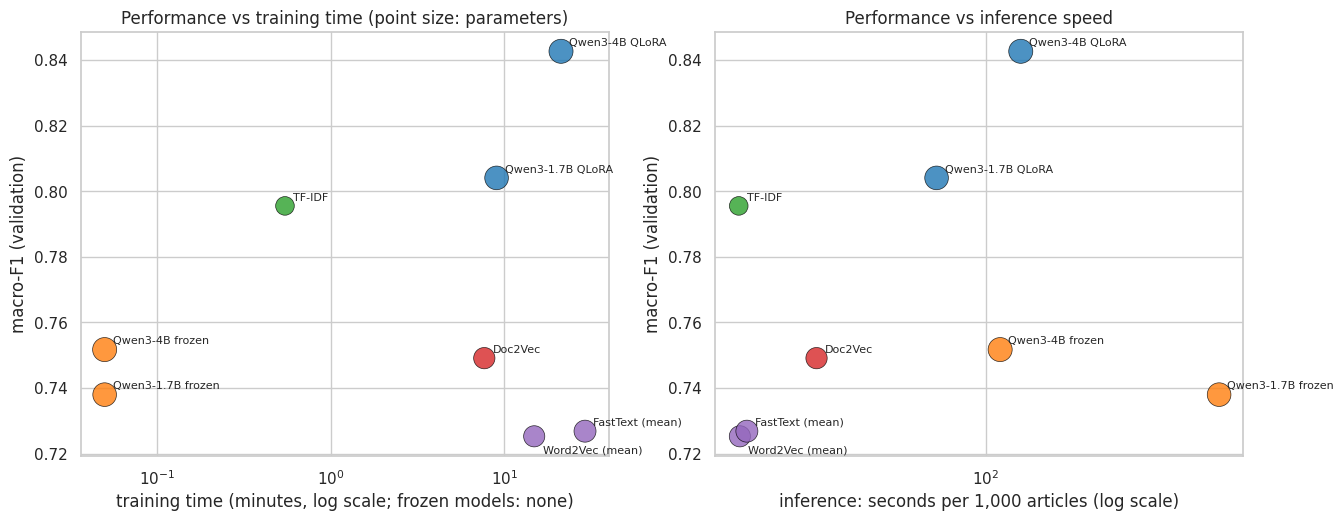

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
t = tradeoffs.copy()
t["train_plot"] = t["train_min"].clip(lower=0.05)             # frozen models: no training, shown at the left edge
for ax, xcol, xlabel in [(axes[0], "train_plot", "training time (minutes, log scale; frozen models: none)"),
                         (axes[1], "infer_s_per_1000", "inference: seconds per 1,000 articles (log scale)")]:
    ax.scatter(t[xcol], t["macro_f1"], s=40 + 260 * np.log10(t["parameters"]) / np.log10(t["parameters"].max()),
               c=t["representation"].map(FAMILY).map(type_colors), alpha=0.8, edgecolors="black", linewidths=0.5)
    for _, r in t.iterrows():
        below = r["representation"] == "Word2Vec (mean)"          # Word2Vec and FastText are close: one label below
        ax.annotate(r["representation"], (r[xcol], r["macro_f1"]), textcoords="offset points",
                    xytext=(6, -12 if below else 4), fontsize=8)
    ax.set(xscale="log", xlabel=xlabel, ylabel="macro-F1 (validation)")
axes[0].set_title("Performance vs training time (point size: parameters)")
axes[1].set_title("Performance vs inference speed")
save_fig(fig, "tradeoffs")

**Interpretation**:
- **Size**: the compact models have about 30 to 27,000 times more parameters than the classical representations (1.7 – 4.0 billion vs 0.15 – 63 million), but QLoRA trains only 0.3 – 0.4% of them (6.4 and 11.8 million), the same order as Word2Vec or Doc2Vec.
- **Training time**: training the classical representations on the full training split takes 8 (Doc2Vec) to 29 minutes (FastText) on the 2 CPU cores of Colab, fine-tuning 9 (Qwen3-1.7B) or 21 minutes (Qwen3-4B) on an L4 GPU. Measured this way, training a classical model from scratch costs as much time as adapting a compact model with QLoRA; the difference is the hardware. The pre-training of the compact models is not counted (it was done by the model provider), while the classical models are trained from scratch.
- **Inference and GPU**: the classical representations need no GPU and process 1,000 articles in 13 – 25 seconds (tokenisation included); the QLoRA models need a GPU with 2.8 or 4.8 GB of memory and 67 or 133 seconds. (The frozen Qwen3-1.7B was run on a slower T4 GPU, so its inference time is not comparable.)
- **Performance per cost**: TF-IDF reaches 94% of the best macro-F1 with about half a minute of training on a CPU. Among the compact models, Qwen3-4B gains 4 points over Qwen3-1.7B on all validation articles but none on the hand-checked ones, for 2.3× the training time, 2× the inference time and 1.7× the GPU memory: **Qwen3-1.7B QLoRA is the better compromise**, as recommended in Part 2.

## 3.6 Insight Extraction
The best representations are now used to analyse the discourse, at two levels:
1. **AI discourse in the whole corpus** (Section 3.6.1): only Doc2Vec has a vector for all 45,462 articles (the compact models were run on 8,037 articles to save GPU time). Its article vectors are clustered into discourse groups, which are followed over time and located relative to the open-models track.
2. **The open-models track** (Sections 3.6.2 – 3.6.4): the best fine-tuned model (Qwen3-4B QLoRA, macro-F1 0.84) assigned a theme to all 4,037 core and mention articles in Part 2. Its predictions are analysed over time, by developer region and by model family.

### 3.6.1 AI discourse in the whole corpus (Doc2Vec)
The Doc2Vec vectors of all articles are clustered with K-means. The number of clusters is chosen among 8 to 16 by the silhouette on a sample of 5,000 articles. Each cluster is described by its most distinctive title words (class-based TF-IDF: words frequent in the titles of the cluster and rare in the other clusters). The clusters are numbered by their share of open-models articles (C00 has the highest share).

In [75]:
from sklearn.feature_extraction.text import CountVectorizer

all_vec = unit(np.vstack(doc_vectors["vector"].to_numpy()).astype(np.float32))
disc = doc_vectors[["doc_id"]].merge(corpus[["doc_id", "quarter", "title", "om_tier", "track"]], on="doc_id")
probe = np.random.default_rng(SEED).choice(len(all_vec), 5000, replace=False)
k_scores = {k: silhouette_score(all_vec[probe], KMeans(k, n_init=5, random_state=SEED).fit_predict(all_vec[probe]),
                                metric="cosine") for k in range(8, 17, 2)}
K = max(k_scores, key=k_scores.get)
print("Silhouette by number of clusters:", {k: round(float(v), 3) for k, v in k_scores.items()}, "-> K =", K)
disc["cluster"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(all_vec)
share = disc.groupby("cluster")["track"].mean().sort_values(ascending=False)
disc["cluster"] = disc["cluster"].map({old: new for new, old in enumerate(share.index)})   # C00 = most open-models articles

# Distinctive title words per cluster (class-based TF-IDF)
cv = CountVectorizer(stop_words="english", min_df=5, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9\-]+\b")
counts = cv.fit_transform(disc.groupby("cluster")["title"].apply(lambda s: " ".join(s.fillna(""))))
tf = normalize(counts, norm="l1", axis=1).toarray()
idf = np.log(K / (counts.toarray() > 0).sum(0))      # 0 for words found in the titles of every cluster
words = np.array(cv.get_feature_names_out())
top_words = {c: ", ".join(words[np.argsort(-(tf[c] * idf))[:7]]) for c in range(K)}

summary = (disc.groupby("cluster").agg(articles=("doc_id", "size"), track_share=("track", "mean"),
                                       core=("om_tier", lambda s: (s == "core").sum()))
           .assign(top_title_words=pd.Series(top_words)))
q_share = pd.crosstab(disc["cluster"], disc["quarter"], normalize="columns")
x = np.arange(q_share.shape[1])
summary["trend_pp_per_year"] = [np.polyfit(x, q_share.loc[c].to_numpy() * 100, 1)[0] * 4 for c in q_share.index]
summary = summary.sort_values("track_share", ascending=False)
summary.to_csv(OUT_DIR / "discourse_clusters.csv")
display(summary.round(3))

Silhouette by number of clusters: {8: 0.061, 10: 0.063, 12: 0.066, 14: 0.067, 16: 0.068} -> K = 16


,articles,track_share,core,top_title_words,trend_pp_per_year
cluster,,,,,
0,2770,0.382,511,"hugging, rag, llms, reasoning, fine-tuning, annotation, transformer",-3.985
1,3138,0.180,149,"hat, coolest, cisco, hpe, servicenow, workloads, hottest",-1.960
2,3105,0.147,173,"trump, ukraine, regulation, war, russia, iran, trade",-1.040
3,3540,0.124,101,"reilly, mcp, coding, cursor, code, github, b2b",8.483
4,2764,0.101,74,"nasdaq, earnings, stocks, shares, q1, holdings, q4",1.114
5,2480,0.089,72,"azure, mcp, foundry, kafka, api, devops, sql",1.788
6,1543,0.068,14,"quantum, hpc, supercomputer, computers, computing, researchers, prize",-1.180
7,3055,0.063,19,"film, books, art, humanity, women, kids, schools",-0.241
8,1774,0.053,14,"samsung, ios, pixel, iphone, ces, macos, apk",0.381


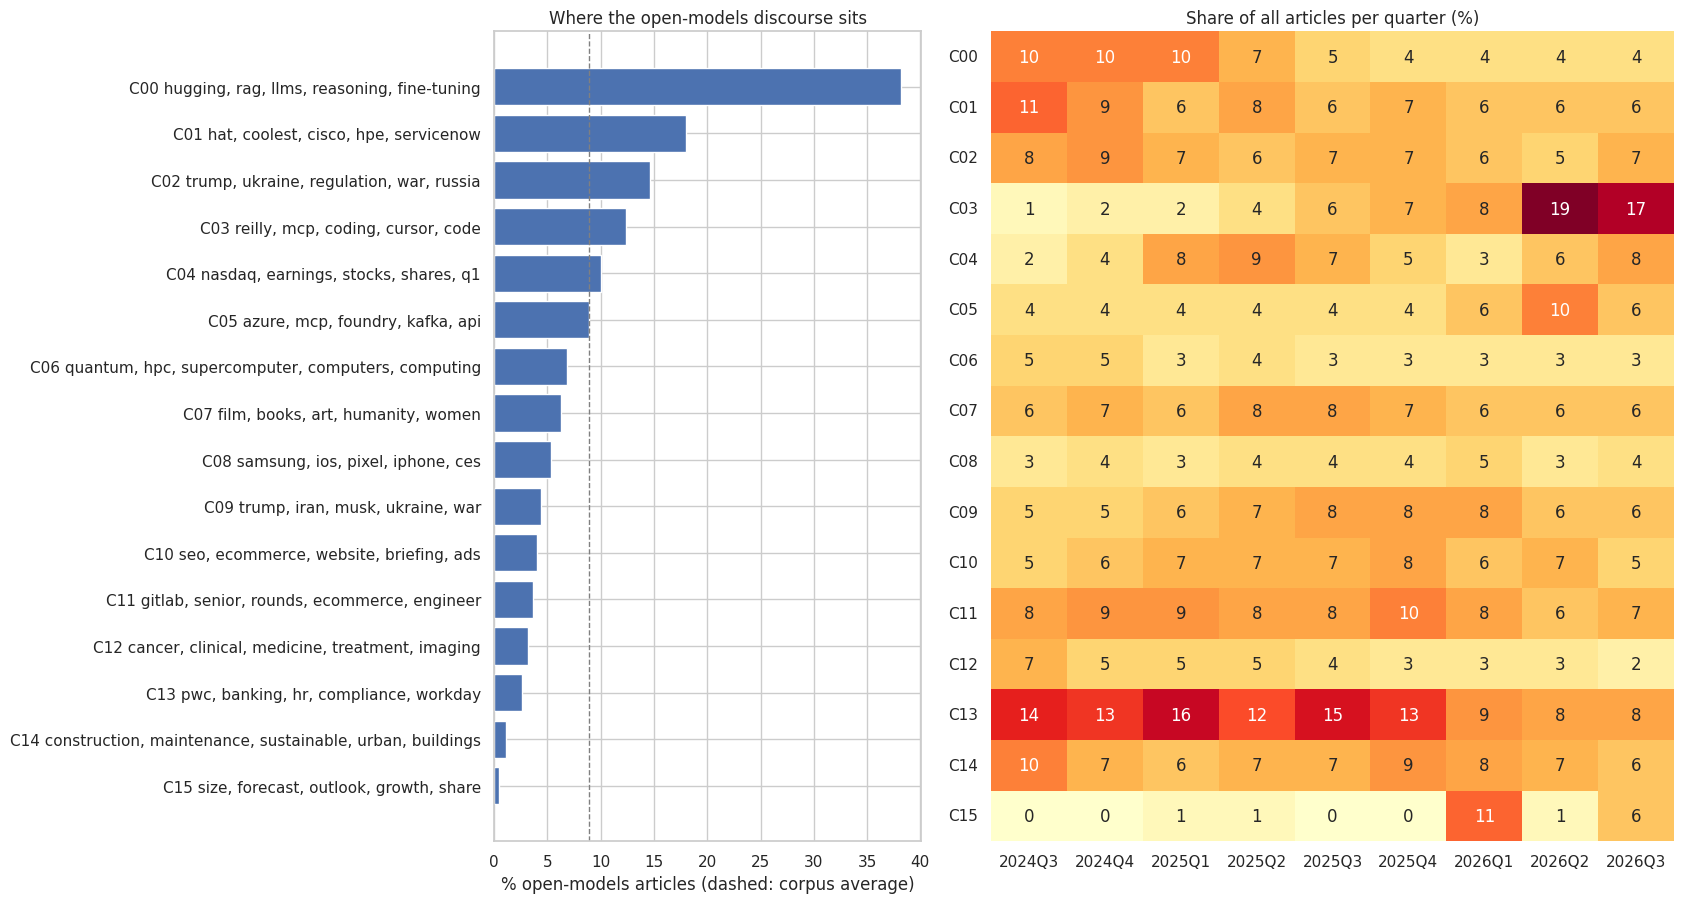

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(17, 0.45 * K + 2), gridspec_kw={"width_ratios": [1, 1.6]})
lab = [f"C{c:02d} {', '.join(top_words[c].split(', ')[:5])}" for c in summary.index]
axes[0].barh(lab[::-1], summary["track_share"][::-1] * 100, color="#4C72B0")
axes[0].axvline(disc["track"].mean() * 100, color="grey", ls="--", lw=1)
axes[0].set(xlabel="% open-models articles (dashed: corpus average)", title="Where the open-models discourse sits")
sns.heatmap((q_share.loc[summary.index] * 100).round(0), annot=True, fmt=".0f", cmap="YlOrRd", cbar=False,
            yticklabels=[f"C{c:02d}" for c in summary.index], ax=axes[1])
axes[1].set(xlabel="", ylabel="", title="Share of all articles per quarter (%)")
axes[1].tick_params(axis="y", rotation=0)
fig.tight_layout()
save_fig(fig, "discourse_clusters")

**Interpretation**: the silhouette is low for every number of clusters (0.06 – 0.07), so the clusters are regions of a continuous discourse rather than separate groups; K = 16 is used to describe it.
- **The open-models discourse sits in four clusters**: **C00**, the technical discourse about LLMs (*Hugging Face*, *RAG*, *reasoning*, *fine-tuning*: 38% open-models articles and 511 core articles, 42% of all core articles); **C01**, enterprise infrastructure (*Red Hat*, *Cisco*, *HPE*, *ServiceNow*: 18%); **C02**, politics, regulation and geopolitics (*Trump*, *regulation*, *trade*, *Ukraine*: 15%); and **C03**, agents and coding tools (*MCP*, *Cursor*, *GitHub*, *coding*: 12%). Open models are almost absent from the clusters about consumer devices, culture and society, marketing, medicine and business management (C07 – C13: 6% or less).
- **The AI discourse shifts towards agents**: C03 grows from 1% of all articles in 2024Q3 to 17 – 19% in 2026Q2 – Q3 (+8.5 points per year), the strongest trend of the corpus, while C00 (technical LLM discourse) falls from 10% to 4% (−4.0 points per year) and C13, the business-management cluster (*PwC*, *banking*, *HR*, *compliance*), from 14% to 8%.
- **For the track**, this means that its main home (C00) is shrinking and that open models increasingly appear in the agent and developer-tool discourse, which matches the theme trends of the next section.
- C15 (*market size*, *forecast*, *outlook*) is a block of market-research press releases (11% of 2026Q1), a reminder that the corpus also contains promotional content.

### 3.6.2 Themes of the open-models track over time
The themes of the 1,210 core articles and of the 2,827 mention articles (which name open models without being centred on them) are taken from the Qwen3-4B QLoRA predictions. The classifier was trained on core articles, so its predictions on mention articles are less reliable; the trends are therefore also shown for the predictions with a confidence of at least 0.6, to check that they do not depend on uncertain predictions. The quarters 2024Q3 and 2026Q3 are incomplete (from 11 September and until 31 August).

Predicted articles by tier: {'mention': 2827, 'core': 1210}
Confidence >= 0.6: 88.6% of all, 86.9% of mention articles


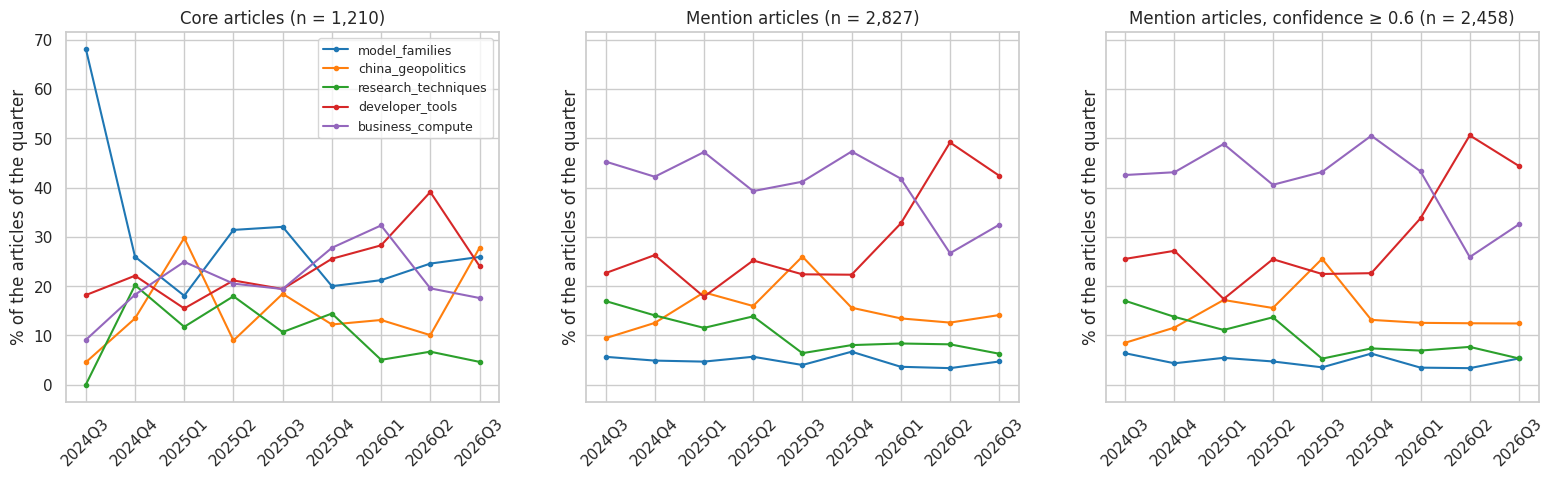

predicted theme                       model_families  china_geopolitics  research_techniques  developer_tools  business_compute
tier    period                                                                                                                 
core    year 1 (Sep 2024 – Jun 2025)            24.4               21.1                 14.3             18.1              22.2
        year 2 (Jul 2025 – Aug 2026)            24.9               15.7                  7.9             28.8              22.6
mention year 1 (Sep 2024 – Jun 2025)             5.1               16.0                 13.1             22.5              43.3
        year 2 (Jul 2025 – Aug 2026)             4.2               15.8                  7.6             36.1              36.2

In [77]:
preds = preds_track.merge(corpus[["doc_id", "om_regions", "om_families"]], on="doc_id", how="left")
print("Predicted articles by tier:", preds["om_tier"].value_counts().to_dict())
print(f"Confidence >= 0.6: {(preds['confidence'] >= 0.6).mean():.1%} of all, "
      f"{(preds.loc[preds['om_tier'] == 'mention', 'confidence'] >= 0.6).mean():.1%} of mention articles")

def theme_shares(df):
    return pd.crosstab(df["quarter"], df["pred"], normalize="index").reindex(columns=LABELS, fill_value=0) * 100

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), sharey=True)
for ax, (title, df) in zip(axes, [("Core articles", preds[preds["om_tier"] == "core"]),
                                  ("Mention articles", preds[preds["om_tier"] == "mention"]),
                                  ("Mention articles, confidence ≥ 0.6", preds[(preds["om_tier"] == "mention") & (preds["confidence"] >= 0.6)])]):
    s = theme_shares(df)
    for theme in LABELS:
        ax.plot(s.index, s[theme], marker="o", ms=3, label=theme, color=palette[theme])
    ax.set(title=f"{title} (n = {len(df):,})", xlabel="", ylabel="% of the articles of the quarter")
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=9)
save_fig(fig, "track_themes_over_time")

year = lambda q: np.where(q < "2025Q3", "year 1 (Sep 2024 – Jun 2025)", "year 2 (Jul 2025 – Aug 2026)")
change = (pd.crosstab([preds["om_tier"], year(preds["quarter"])], preds["pred"], normalize="index")
          .reindex(columns=LABELS) * 100).rename_axis(index=["tier", "period"], columns="predicted theme")
change = change.loc[["core", "mention"]]
change.to_csv(OUT_DIR / "track_themes_by_year.csv")
display(change.round(1))

In [78]:
# Hand check by the author: 20 random mention articles with their predicted theme
check = (preds[preds["om_tier"] == "mention"].sample(20, random_state=1)
         .merge(corpus[["doc_id", "title", "text"]], on="doc_id"))
check["start"] = check["text"].str[:300]
display(check[["title", "start", "pred", "confidence"]])

,title,start,pred,confidence
0,Multimodal Retrieval-Augmented Generation (RAG) with Document Retrieval (ColPali) and Vision Language Models (VLMs) ...,🚨 WARNING: This notebook is resource-intensive and requires substantial computational power. If you’re running this ...,developer_tools,0.996177
1,How Retrieval Augmented Generation (RAG) Makes LLM Smarter,"Large language models (LLMs) are like ultimate know-it-alls, ready to chat about any topic you throw their way—wheth...",developer_tools,0.920358
2,Experts: You have some power to reduce your AI environmental footprint,"Amazon Web Services data center is visible on Aug. 22, 2024, in Boardman, Ore. (AP Photo/Jenny Kane, File)\n\nWASHIN...",china_geopolitics,0.677947
3,"A data bottleneck is holding AI science back, says new Nobel winner",AI’s usefulness for scientific discovery will be stunted without high-quality data.\n\nDavid Baker is sleep-deprived...,china_geopolitics,0.740085
4,What we announced at Google for Brazil 2025,Google is celebrating 20 years in Brazil with new AI tools and initiatives. Expect real-time translation in Google M...,business_compute,0.925293
5,I met the ‘ godfathers of AI’ in Paris – here’s what they told me to really worry about,Experts are split between concerns about future threats and present dangers. Both camps issued dire warnings\n\nI wa...,china_geopolitics,0.984685
6,Tools and Talks Worth Checking Out at KubeCon Europe,"Are you heading to KubeCon + CloudNativeCon Europe 2025? With the event fast approaching, now’s the perfect time to ...",developer_tools,0.968983
7,Data Points: OpenAI looks inside neural networks,An interpretability team at OpenAI developed a new training method that forces language models to use far fewer conn...,model_families,0.577142
8,"Codex’s Robot Dev Team, Grok's Fixation on South Africa, Saudi Arabia’s AI Power Play, and more...","In the age of AI, large corporations — not just startups — can move fast. I often speak with large companies’ C-suit...",business_compute,0.960425
9,Connected Intelligence: Operationalizing Production-Grade Graph Solutions Across Enterprise Networks,"The race for enterprise AI dominance has officially shifted from basic model experimentation to massive, production-...",developer_tools,0.812492


In [79]:
# Robustness checks suggested by the hand check
mention = preds[preds["om_tier"] == "mention"]
for t in (0.6, 0.8):
    s = mention[mention["confidence"] >= t]
    print(f"Mention articles with confidence >= {t}: {len(s):,} ({len(s) / len(mention):.0%})")
    display((pd.crosstab(year(s["quarter"]), s["pred"], normalize="index").reindex(columns=LABELS) * 100).round(1))

# Theme profile by region on the core articles only (where the classifier was evaluated in Part 2)
core_one = preds[(preds["om_tier"] == "core") & (preds["om_regions"].map(len) == 1)]
core_one = core_one.assign(region=core_one["om_regions"].map(lambda r: r[0]))
print("Core articles only, theme profile by region (%):")
display((pd.crosstab(core_one["region"], core_one["pred"], normalize="index").reindex(columns=LABELS) * 100)
        .round(0).loc[["US", "China", "Europe"]])

Mention articles with confidence >= 0.6: 2,458 (87%)


pred,model_families,china_geopolitics,research_techniques,developer_tools,business_compute
row_0,,,,,
year 1 (Sep 2024 – Jun 2025),5.0,15.0,12.8,22.7,44.4
year 2 (Jul 2025 – Aug 2026),4.1,15.0,6.7,37.1,37.0


Mention articles with confidence >= 0.8: 2,001 (71%)


pred,model_families,china_geopolitics,research_techniques,developer_tools,business_compute
row_0,,,,,
year 1 (Sep 2024 – Jun 2025),4.5,13.9,13.0,23.0,45.7
year 2 (Jul 2025 – Aug 2026),4.0,13.4,6.3,39.4,36.9


Core articles only, theme profile by region (%):


pred,model_families,china_geopolitics,research_techniques,developer_tools,business_compute
region,,,,,
US,32.0,5.0,11.0,32.0,20.0
China,19.0,36.0,10.0,10.0,26.0
Europe,19.0,6.0,6.0,34.0,34.0


**Hand check of the predictions on mention articles.** The classifier was evaluated on core articles only (Part 2), so its predictions on mention articles had not been checked. A random sample of 20 mention articles (fixed seed) was labelled with the annotation rubric of Part 2, from the title and the beginning of the text. The labels were proposed by Claude and reviewed by the author.

| # | predicted | verdict | better theme |
|---|---|---|---|
| 0 | developer_tools | correct | |
| 1 | developer_tools | correct | |
| 2 | china_geopolitics | wrong | business_compute or none (energy use of data centres) |
| 3 | china_geopolitics | wrong | research_techniques (AI in science) |
| 4 | business_compute | debatable | none |
| 5 | china_geopolitics | debatable | research_techniques (AI risk) |
| 6 | developer_tools | correct | |
| 7 | model_families | debatable | research_techniques (newsletter, mixed items) |
| 8 | business_compute | correct | |
| 9 | developer_tools | correct | |
| 10 | business_compute | correct | |
| 11 | business_compute | correct | |
| 12 | model_families | debatable | developer_tools (prompting guide) |
| 13 | developer_tools | correct | |
| 14 | business_compute | correct | |
| 15 | business_compute | none fits | none (architecture) |
| 16 | china_geopolitics | wrong | research_techniques (safety study) |
| 17 | business_compute | correct | |
| 18 | developer_tools | correct | |
| 19 | china_geopolitics | wrong | research_techniques (LeCun, world models) |

**Result: 11 correct, 4 debatable, 4 wrong, 1 outside the five themes.**
- **`china_geopolitics` works as a catch-all**: all 4 wrong predictions are `china_geopolitics`, and none of the 5 `china_geopolitics` predictions in the sample is clearly correct. General news about AI and society is put into the policy theme, so its share among the mention articles (about 16%) is likely overestimated.
- **`developer_tools` is reliable**: all 6 predictions are correct, which supports the main trend of this section.
- **The classifier cannot predict *none***: an article outside the five themes (#15) still receives one.
- **Confidence**: the threshold of 0.6 removes only 1 of the 5 errors, while all correct predictions have a confidence of at least 0.81 and 4 of the 5 errors are below 0.8. With a threshold of 0.8 (cell above), 71% of the mention articles are kept and the trends are the same: `developer_tools` grows from 23% to 39%, `research_techniques` falls from 13% to 6%.
- **Regions**: on the core articles alone, where the classifier was evaluated, Chinese models are discussed through geopolitics even more clearly (36% vs 5% for US models, cell above), so the regional finding of Section 3.6.3 does not depend on the mention articles.
- With 20 articles, one article is 5 percentage points: the check shows the type of errors, not a precise error rate.

**Interpretation**:
- **`developer_tools` is the growing theme**: from 18% to 29% of the core articles and from 23% to 36% of the mention articles between the two years, with a peak in 2026Q2 (39% and 49%). Open models are more and more discussed as components of agents, coding assistants and platforms.
- **`research_techniques` shrinks** (core 14% → 8%, mention 13% → 8%), and **`china_geopolitics`** peaks in the core articles in 2025Q1, the quarter of DeepSeek-R1 (30%), then falls (21% → 16% between the years).
- **`model_families`** stays stable among the core articles (about 25%) and is small among the mention articles (4 – 5%), as expected: these articles name a model without being about it. `business_compute` is the largest theme of the mention articles, but loses ground to `developer_tools` (43% → 36%).
- **The trends hold with stricter filters**: 87% of the mention articles have a confidence of at least 0.6 and 71% of at least 0.8, and all subsets show the same changes (right panel and hand check above). The hand check shows, however, that `china_geopolitics` is overestimated among the mention articles, while `developer_tools` is reliable. The first and the last quarters are incomplete (2024Q3 starts on 11 September with few core articles, hence the 68% for `model_families`).

### 3.6.3 Themes by developer region and model family
Every open-models article lists the model families it mentions and the home region of their developers (Stage 1 lexicon). An article that mentions families of one region only is assigned to that region; the theme profile of each region and of the most mentioned families shows **how** each group of open models is discussed.

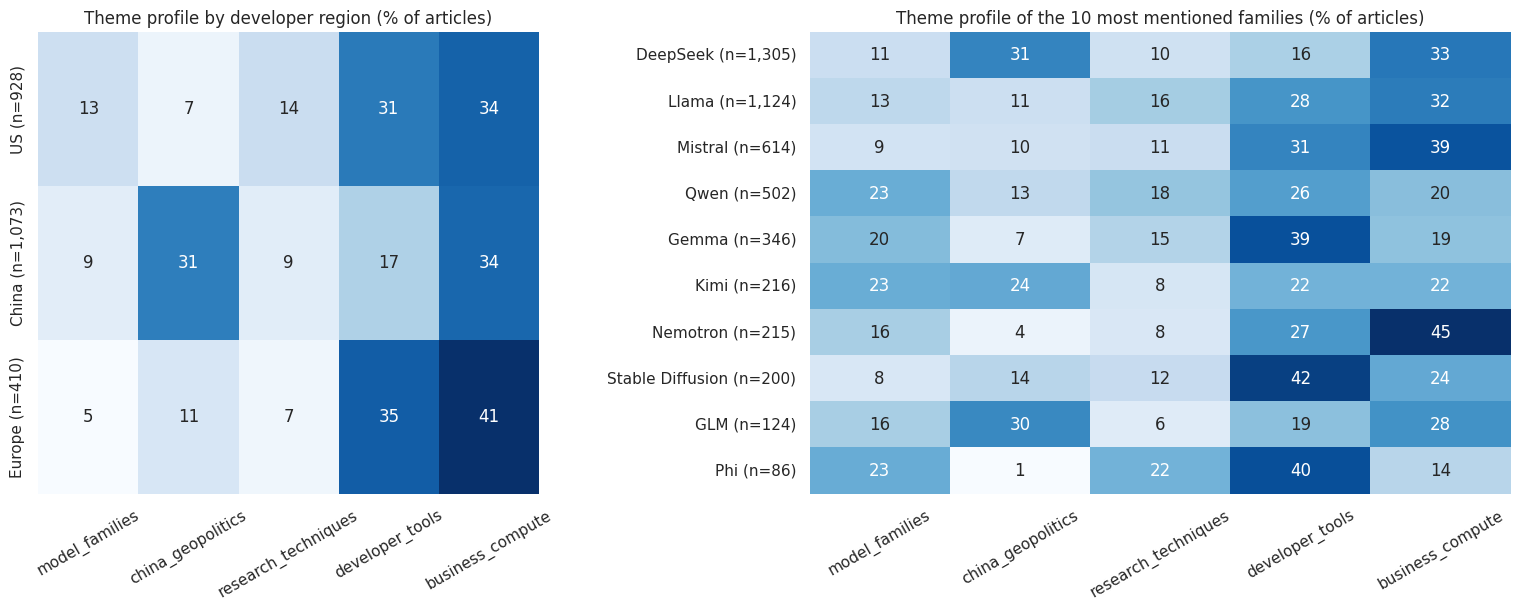

In [80]:
one_region = (preds[preds["om_regions"].map(len) == 1].assign(region=lambda d: d["om_regions"].map(lambda r: r[0]))
              .reset_index(drop=True))
by_region = pd.crosstab(one_region["region"], one_region["pred"], normalize="index").reindex(columns=LABELS) * 100
by_region["articles"] = one_region["region"].value_counts()
by_region = by_region.loc[["US", "China", "Europe"]]

fam = preds.explode("om_families").dropna(subset=["om_families"]).reset_index(drop=True)
top_fam = fam["om_families"].value_counts().head(10).index
by_family = pd.crosstab(fam.loc[fam["om_families"].isin(top_fam), "om_families"],
                        fam.loc[fam["om_families"].isin(top_fam), "pred"], normalize="index").reindex(columns=LABELS) * 100
by_family["articles"] = fam["om_families"].value_counts()
by_family = by_family.loc[top_fam]
by_family.index = pd.Index([lexicon["families"][f]["label"].split(" / ")[0] for f in by_family.index], name="family")
by_region.to_csv(OUT_DIR / "track_themes_by_region.csv"); by_family.to_csv(OUT_DIR / "track_themes_by_family.csv")

fig, axes = plt.subplots(1, 2, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 1.4], "wspace": 0.45})
sns.heatmap(by_region[LABELS], annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[0],
            yticklabels=[f"{r} (n={n:,})" for r, n in by_region["articles"].items()])
axes[0].set(title="Theme profile by developer region (% of articles)", xlabel="", ylabel="")
sns.heatmap(by_family[LABELS], annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[1],
            yticklabels=[f"{f} (n={n:,})" for f, n in by_family["articles"].items()])
axes[1].set(title="Theme profile of the 10 most mentioned families (% of articles)", xlabel="", ylabel="")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
save_fig(fig, "track_themes_region_family")

**Interpretation**:
- **Chinese models are discussed through geopolitics**: 31% of the articles that mention only Chinese families are about China–US rivalry and policy, against 7% for US and 11% for European models. US and European models are discussed mainly through **developer tools and business** (66% and 77% together).
- **DeepSeek is the extreme case** (31% `china_geopolitics`, 33% `business_compute`: the "DeepSeek shock" on costs, chips and markets), while **Qwen** is discussed like a US model, as a model and a tool (23% `model_families`, 26% `developer_tools`, only 13% `china_geopolitics`). Kimi and GLM are in between (24% and 30% `china_geopolitics`).
- **Each US family has its own profile**: Gemma and Phi are discussed as developer tools (39 – 40%), Phi also as research (22%, small models); Nemotron through business and compute (45%, NVIDIA hardware); Llama has the most balanced profile, as the reference open model.
- These profiles complete Stage 1, which found that attention moved from Llama to Chinese families: the Chinese families did not only gain attention, they brought a geopolitical framing into the track.

### 3.6.4 Fine-tuned themes and Stage 1 topics
Stage 1 described the core articles with 16 NMF topics; Part 2 mapped them to the five themes (topic labels). On the core articles, the share of agreement between the Stage 1 topic theme and the predicted theme shows how much the fine-tuned model changes the picture of the track, and on the validation articles, which of the two agrees with the reviewed labels.

In [81]:
TOPIC_TO_THEME = {t: theme for theme, ts in {"model_families": ["T08", "T09", "T11", "T13", "T15"],
                                              "china_geopolitics": ["T02", "T07"],
                                              "research_techniques": ["T01", "T05", "T06"],
                                              "developer_tools": ["T04", "T10"],
                                              "business_compute": ["T03", "T12", "T14"]}.items() for t in ts}
cmp_ = preds[preds["om_tier"] == "core"].merge(core, on="doc_id")
cmp_["topic_theme"] = cmp_["dominant_topic_label"].str[:3].map(TOPIC_TO_THEME)
cmp_ = cmp_.dropna(subset=["topic_theme"]).merge(labels[["doc_id", "checked_theme", "split"]], on="doc_id", how="left")
v = cmp_[(cmp_["split_y"] == "validation") & (cmp_["checked_theme"] != "none") & cmp_["checked_theme"].notna()]
agree = pd.Series({
    "core articles: topic theme = predicted theme": (cmp_["topic_theme"] == cmp_["pred"]).mean(),
    "validation: topic theme = reviewed label": (v["topic_theme"] == v["checked_theme"]).mean(),
    "validation: predicted theme = reviewed label": (v["pred"] == v["checked_theme"]).mean()})
display(agree.round(3).to_frame("agreement"))

year_topic = pd.crosstab(year(cmp_["quarter"]), cmp_["topic_theme"], normalize="index").reindex(columns=LABELS) * 100
year_pred = pd.crosstab(year(cmp_["quarter"]), cmp_["pred"], normalize="index").reindex(columns=LABELS) * 100
display(pd.concat({"Stage 1 topic themes": year_topic, "fine-tuned themes": year_pred})
        .rename_axis(index=["themes", "period"], columns="theme").round(1))

,agreement
core articles: topic theme = predicted theme,0.598
validation: topic theme = reviewed label,0.592
validation: predicted theme = reviewed label,0.850


theme                                              model_families  china_geopolitics  research_techniques  developer_tools  business_compute
themes               period                                                                                                                 
Stage 1 topic themes year 1 (Sep 2024 – Jun 2025)            19.0               22.9                 21.3             12.2              24.7
                     year 2 (Jul 2025 – Aug 2026)            24.2               11.2                 13.4             32.7              18.6
fine-tuned themes    year 1 (Sep 2024 – Jun 2025)            25.9               20.0                 13.1             17.9              23.1
                     year 2 (Jul 2025 – Aug 2026)            26.3               15.0                  7.6             27.7              23.4

**Interpretation**:
- **The fine-tuned model agrees with the Stage 1 topics for only 60% of the core articles**, and on the validation articles it agrees much better with the reviewed labels (0.85) than the topic themes do (0.59, consistent with the 64% of the hand check in Part 2). The fine-tuned themes are therefore the more reliable picture of the track.
- **The direction of the trends is the same**: both show `developer_tools` growing and `china_geopolitics` and `research_techniques` shrinking between the two years. The Stage 1 topics **exaggerate the changes** (`developer_tools` 12% → 33% vs 18% → 28%; `china_geopolitics` 23% → 11% vs 20% → 15%): a topic model follows the dominant vocabulary of each period, while the classifier assigns the main subject of each article.
- The main Stage 1 findings on the themes of the track hold, with smaller effect sizes.

### 3.6.5 Which representation captures the open-models track best?
The table brings together, for every representation, its score on the four questions of this part: semantic similarity of articles, separation of the open-models articles, theme classification, and cost.

In [82]:
synthesis = pd.DataFrame({
    "kNN accuracy (themes)": intrinsic_docs["kNN accuracy"],
    "NMI (themes)": intrinsic_docs["NMI"],
    "10-NN purity (track)": track_sep["10-NN purity (all)"],
    "macro-F1": extrinsic.set_index("representation")["macro_f1"],
    "macro-F1 hand-checked": extrinsic.set_index("representation")["macro_f1_hand"],
    "training (min)": tradeoffs.set_index("representation")["train_min"],
    "GPU needed": tradeoffs.set_index("representation")["peak_gpu_gb"].gt(0).map({True: "yes", False: "no"}),
}).loc[list(REP)]
synthesis.to_csv(OUT_DIR / "synthesis.csv")
display(synthesis.round(3))

,kNN accuracy (themes),NMI (themes),10-NN purity (track),macro-F1,macro-F1 hand-checked,training (min),GPU needed
representation,,,,,,,
TF-IDF,0.655,0.274,0.672,0.796,0.754,0.546,no
Word2Vec (mean),0.636,0.317,0.693,0.725,0.729,14.832,no
FastText (mean),0.626,0.318,0.694,0.727,0.743,29.083,no
Doc2Vec,0.646,0.338,0.716,0.749,0.740,7.656,no
Qwen3-1.7B frozen,0.646,0.287,0.673,0.738,0.713,0.000,yes
Qwen3-1.7B QLoRA,0.762,0.495,0.671,0.804,0.796,9.008,yes
Qwen3-4B frozen,0.660,0.309,0.681,0.752,0.754,0.000,yes
Qwen3-4B QLoRA,0.762,0.484,0.673,0.843,0.788,21.158,yes


**Interpretation**: no single representation is best for every purpose.
- **To analyse the themes of the open-models track: Qwen3-1.7B QLoRA.** The QLoRA vectors are the only ones with a clear theme structure (kNN 0.76, NMI 0.50), and the smaller model matches the larger one on the intrinsic tests and on the hand-checked labels at a lower cost. Qwen3-4B QLoRA gives the best macro-F1 on all labels and was used for the predictions of Section 3.6.
- **To place the track within the whole AI discourse: Doc2Vec.** It separates the open-models articles best without supervision (0.72) and has a vector for every article of the corpus, which made the discourse clusters of Section 3.6.1 possible.
- **Without a GPU: TF-IDF.** It is the best classical representation for theme classification (0.80) and the cheapest of all.
- **At word level: Word2Vec** for similarity and categories, **FastText** for unseen names and analogies.
- The frozen compact models are dominated: they need a GPU and score no better than the classical representations.

## 3.7 Summary: Model Trade-offs and Insights from the Open-Models Track
**Model trade-offs**
- **Fine-tuning pays off for theme structure, pre-training alone does not.** The QLoRA models give the best article vectors (kNN accuracy 0.76) and the best theme classification (0.84 and 0.80 macro-F1). The frozen compact models score like the classical representations trained on the corpus.
- **A strong discrete baseline nearly closes the gap.** TF-IDF reaches 0.80 macro-F1, not significantly below the best QLoRA model, without a GPU and with less than a minute of training. Dense classical representations (Word2Vec, FastText, Doc2Vec) are 5 – 7 points lower.
- **Model size matters less than fine-tuning.** Qwen3-4B is not better than Qwen3-1.7B on the hand-checked articles, at 2.3× the training time and 1.7× the GPU memory; Qwen3-1.7B QLoRA is the recommended compact model.
- **Classical models remain useful where they cover the whole corpus**: Doc2Vec separates the open-models articles best without supervision and is cheap enough to embed all 45,462 articles.

**Insights on the open-models track**
- **Where the track sits**: open models are concentrated in the technical LLM discourse, enterprise infrastructure, politics and regulation, and agents, and almost absent from consumer, culture, medicine and business-management coverage.
- **From research to tools**: the share of open-models articles about developer tools and agents grows by about 10 points between the two years (core 18% → 29%, mention 23% → 36%), while research and China–US rivalry lose weight. The same shift is visible in the whole corpus, where the agent cluster grows from 1% to 17 – 19% of all articles.
- **Two ways of talking about open models**: Chinese models are framed by geopolitics (31% of their articles, DeepSeek above all), US and European models by tools and business; Qwen is the exception among the Chinese families.
- **Stage 1 revisited**: the trends of the Stage 1 topics hold in direction but are exaggerated; the fine-tuned classifier agrees much better with the reviewed labels (0.85 vs 0.59).

**Limitations**
- **Small evaluation set**: 206 validation articles (98 checked by hand) give bootstrap intervals of about ±6 points; several differences between representations are not significant.
- **Labels**: the training labels and part of the validation labels were made with an LLM (Part 2, Section 2.2.3); the scores on the hand-checked articles are reported to control for this.
- **Unequal intrinsic comparison**: the QLoRA vectors were trained on the five themes, so their intrinsic theme scores are not unsupervised like those of the other representations.
- **Timing**: the classical models were timed on a 10% sample and scaled, on a 2-core CPU; the compact models on Colab GPUs (L4, T4 for the frozen Qwen3-1.7B). The times are comparable in order of magnitude only, and the pre-training cost of the compact models is not included.
- **Predictions on mention articles**: the classifier was trained on core articles and cannot predict *none*. A hand check of 20 mention articles (Section 3.6.2) found 11 correct, 4 debatable and 5 wrong predictions, mostly `china_geopolitics` given to general AI news; its share among the mention articles is likely overestimated. The predicted probabilities are not calibrated.
- **Regions**: only articles mentioning families of a single region are used; an article mentioning both DeepSeek and Llama is left out of the region profile.
- **Discourse clusters**: the silhouette is low (0.07) and the number of clusters was chosen at the upper end of the tested range, so the clusters describe regions of a continuous discourse, not natural groups; K-means on 45,462 articles can also differ slightly between machines, so the cluster sizes are indicative. They are based on Doc2Vec only, the one representation available for all articles.

## 3.8 Outputs and Handover
All outputs are saved in `OUT_DIR` on Google Drive (`HSLU/CLT/extraction_outputs/stage2/wp3`); the small tables and figures are also copied to `artifacts/stage2_wp3/` in the repository.

| file | content |
|---|---|
| `intrinsic_words_general.csv`, `intrinsic_words_developers.csv`, `intrinsic_words_categories.csv` | word-level intrinsic scores (Section 3.2) |
| `intrinsic_articles_themes.csv`, `intrinsic_articles_track.csv` | article-level intrinsic scores (Section 3.3) |
| `extrinsic_theme_classification.csv`, `extrinsic_paired.csv` | theme classification of all representations, paired bootstrap (Section 3.4) |
| `tradeoffs.csv`, `timing_classical.json` | size, time, GPU memory and scores of every representation (Section 3.5) |
| `discourse_clusters.csv` | Doc2Vec discourse clusters of the whole corpus (Section 3.6.1) |
| `track_themes_by_year.csv`, `track_themes_by_region.csv`, `track_themes_by_family.csv` | themes of the open-models track (Sections 3.6.2 – 3.6.3) |
| `synthesis.csv` | overview of all representations (Section 3.6.5) |
| `tokens_sample.parquet` | tokens of the 8,037 compared articles (cache) |
| `figures/` | visualisations |

In [83]:
import shutil
ART = REPO / "artifacts/stage2_wp3"
(ART / "figures").mkdir(parents=True, exist_ok=True)
for f in OUT_DIR.iterdir():
    if f.suffix in {".csv", ".json"}:
        shutil.copy(f, ART / f.name)
for f in FIG.glob("*.png"):
    shutil.copy(f, ART / "figures" / f.name)
for f in sorted(ART.rglob("*")):
    if f.is_file():
        print(f"{f.relative_to(REPO)}  ({f.stat().st_size / 1e3:.0f} kB)")

artifacts/stage2_wp3/discourse_clusters.csv  (2 kB)
artifacts/stage2_wp3/extrinsic_paired.csv  (0 kB)
artifacts/stage2_wp3/extrinsic_theme_classification.csv  (1 kB)
artifacts/stage2_wp3/figures/discourse_clusters.png  (269 kB)
artifacts/stage2_wp3/figures/extrinsic_theme_classification.png  (92 kB)
artifacts/stage2_wp3/figures/intrinsic_articles.png  (104 kB)
artifacts/stage2_wp3/figures/track_themes_over_time.png  (223 kB)
artifacts/stage2_wp3/figures/track_themes_region_family.png  (169 kB)
artifacts/stage2_wp3/figures/tradeoffs.png  (104 kB)
artifacts/stage2_wp3/figures/tsne_validation_themes.png  (233 kB)
artifacts/stage2_wp3/figures/words_category_purity.png  (84 kB)
artifacts/stage2_wp3/intrinsic_articles_themes.csv  (1 kB)
artifacts/stage2_wp3/intrinsic_articles_track.csv  (1 kB)
artifacts/stage2_wp3/intrinsic_words_categories.csv  (0 kB)
artifacts/stage2_wp3/intrinsic_words_developers.csv  (0 kB)
artifacts/stage2_wp3/intrinsic_words_general.csv  (1 kB)
artifacts/stage2_wp3/syn

### AI Disclosure
Claude (Claude Opus 5.5) was used as a coding and writing assistant in this work package. It supported:
- writing and debugging the evaluation code, and re-using the functions and settings of Parts 1 and 2;
- choosing and implementing the evaluation measures (intrinsic benchmarks, kNN and clustering scores, paired bootstrap);
- drafting the interpretation text from the computed results;
- proposing the labels of the hand check of Section 3.6.2, which the author reviewed.

The author ran the notebook in Colab and reviewed the hand-check labels. The scope of the comparison, the review of the code, figures and results, and the final interpretations are the responsibility of the author of this work package.